# AgentBot MCP-RAG de críticas

### Un chatbot que elige su herramienta: críticas de usuarios o ficha técnica, y cita de dónde sale cada cosa

Grupo Tango: Gustavo Betancur · Mike Martinez · Pedro Jojoa · Juan Sebastian Orozco

La sesión 5 nos dejó un RAG monolítico: cada pregunta pasa por el mismo recuperador y el mismo
prompt. Aquí seguimos con las mismas críticas de FilmAffinity, pero la recuperación se separa en
**dos servidores MCP propios** (el buscador de opiniones y la ficha técnica) y un agente (Llama 3.2
en Ollama) que **decide qué herramienta usar** en cada pregunta —o ninguna, con la señal de
abstención que lleva el buscador. Es la sesión 6 del curso: herramientas, agentes y MCP.

| Sección | Contenido |
|---|---|
| 1. El problema | De RAG monolítico a agente; el guía y sus trampas; cómo medimos; hipótesis |
| 2. Andamiaje | Entorno, dependencias, Ollama sin terminal, estilo, texto |
| 3. Corpus e índice | El índice de la sesión 5, congelado; umbral de abstención; snapshot |
| 4. Servidores MCP propios | Dos servidores FastMCP (puertos 9082/9083), cliente y equivalencia |
| 5. El agente | `create_react_agent` y los tres modos: Autónomo, Guiado, Determinístico |
| 6. Experimentos | Routing, abstención, latencias, llama contra qwen, citas |
| 7. El chatbot | La interfaz en Gradio y el guion del video |
| 8. Veredicto, costos y conclusiones | Las cinco hipótesis, lo que costó y conclusiones |

---

## 1. El problema

### 1.1 Del RAG monolítico al agente

El chatbot de la sesión 5 resolvía todo con una sola cadena: recupera cinco fragmentos, redacta.
Funcionó bien para opiniones, pero en el diagnóstico de §5.4 apareció la fisura: **la ficha técnica
llegó al contexto solo en el 65% de las preguntas de datos** (el apellido del director llegaba al
98%, porque las críticas casi siempre lo nombran), y la conclusión literal fue *"hace falta un
recuperador que traiga siempre la ficha cuando la pregunta es de datos"*.

Hay dos formas de arreglarlo. Una: meter más heurísticas en la cadena. La otra, la de esta sesión:
separar el conocimiento en **servicios con herramienta propia** y dejar que un agente con
*ReAct* (Yao *et al.*, 2022) decida. El agente mira la pregunta, llama a la herramienta que hace
falta —al buscador si la pregunta es de opiniones, a la ficha si es de datos, a las dos si son
ambas cosas— y redacta citando lo que recibió. Si la pregunta es sobre una película que no está en
el índice, la señal del servidor le dice que no hay con qué responder, y lo dice.

El protocolo **MCP** (*Model Context Protocol*) es lo que convierte esas herramientas en piezas
independientes: los servidores exponen sus funciones por HTTP y cualquier cliente —aquí LangChain
con `langchain-mcp-adapters`— las descubre y las llama sin conocer su código.

### 1.2 El notebook guía y las cuatro trampas

La sesión tiene tres guías: `1-herramientas-y-agentes-con-ollama` (herramientas locales y
`create_react_agent`), `2-mcp-langchain-ollama` (las mismas herramientas movidas a dos servidores
MCP) y `3-chatbot-con-mcp-y-gradio` (opcional; los servidores detrás de una interfaz). Lo que **no
copiamos**: sus ejemplos (calculadora y clima de Open-Meteo), prohibidos por la consigna. Cambiamos
el dominio completo: críticas y fichas de FilmAffinity con servidores nuestros.

Del guía nos llevamos (y corregimos) cuatro trampas que mediremos:

1. **El guía no mide nada.** Todas sus demos son anecdóticas. Aquí cada pregunta tiene etiqueta de
   herramienta esperada y cada configuración un número.
2. **llama3.2:3b a veces no invoca la herramienta.** El guía lo sufre y lo narra; nosotros lo
   convertimos en métrica (routing por modo) y en el experimento llama contra `qwen2.5:3b`, que el
   propio guía sugiere como alternativa más fiable.
3. **stdio no corre en Colab.** Los servidores del guía usan transporte `streamable-http` en Colab
   por eso mismo; los nuestros hacen lo mismo desde el arranque (§4).
4. **Los servidores se levantan a mano.** El guía pide abrir terminales aparte y recordar apagarlos.
   Aquí se materializan desde el notebook, se levantan con un *health-check*, y la celda final los
   apaga.

### 1.3 Cómo se mide

Toda pregunta nueva lleva un **rótulo de intención** que dice qué herramienta debería usar el agente:

| Conjunto | n | Pregunta tipo | Herramienta esperada |
|---|---|---|---|
| **RT** · opiniones | 40 | «¿Qué opinan los usuarios de X?» | `buscar_criticas` |
| **RF** · ficha | 40 | «¿Quién dirigió X y en qué año se estrenó?» | `ficha_pelicula` |
| **RA** · ambas | 30 | «¿Vale la pena ver X? ¿Quién la dirigió?» | las dos |
| **RS** · seguimiento | 20 | «¿Y qué dicen de la música?» (con historial) | `buscar_criticas` |
| **RD** · abstención | 70 | «¿Qué opinan de X?» con X fuera del índice o inventada | ninguna: abstenerse |

Sobre RT/RF/RA/RS medimos **routing** (¿llamó a la herramienta esperada? ¿a alguna de más?), la
**calidad de lo que trae el buscador** (precisión de película@5 y MRR sobre las fuentes `[F n]`,
igual que §4 y §5 de la sesión 5) y la **latencia** por vía (directo sin agente, agente en modo
Determinístico y agente Autónomo, sobre las mismas preguntas). En RD medimos la **abstención**
correcta y falsa, con la señal del servidor y sin ella. Todo el notebook se puede correr desde
cero en Colab: instala dependencias, descarga corpus y modelos, levanta los servidores y escribe
sus `resultados/`.

### 1.4 Las cinco hipótesis

Cada una con su criterio, declarado antes de correr:

> **H1 · El agente acierta el routing.** En Autónomo, llama a la herramienta esperada (o a las dos
> en RA) en al menos el 75% de RT y RF.
> **H2 · El modo Guiado arregla lo que el Autónomo rompe.** Donde el Autónomo falla, el Guiado sube
> el routing exacto por lo menos 15 puntos.
> **H3 · La capa MCP cuesta poco.** El sobrecosto mediano de pasar por MCP (Determinístico contra
> directo) es menor de un segundo por pregunta.
> **H4 · Qwen invoca mejor las herramientas que Llama**, como sugiere el guía: en Autónomo, el
> routing exacto de qwen2.5:3b supera al de llama3.2:3b por lo menos 10 puntos.
> **H5 · La señal del servidor es la que enseña a abstenerse.** Con la señal activa, la abstención
> correcta es ≥ 90% y la falsa ≤ 10%; con el umbral apagado en el servidor, la correcta cae por lo
> menos 20 puntos.

---

## 2. Andamiaje

### 2.1 Presupuesto y entorno

Mismo presupuesto que la sesión 5: unas 300 películas en el índice y fragmentos de 200 tokens.
Con `HUMO_FORZAR = True` (editable aquí mismo, cómodo en Colab) todo baja al mínimo para probar el
notebook entero en pocos minutos y sin GPU. El modo `Determinístico` y el umbral del buscador son
los nuevos del presupuesto: `PUERTO_*` son de nuestros servidores (los del guía, 9080/9081, quedan
libres por si corren en la misma sesión).

In [6]:
import os, re, json, time, random, shutil, hashlib, subprocess, warnings, unicodedata, ast, bisect
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"   # sin barras de descarga en las salidas

try:
    import google.colab          # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

HUMO_FORZAR = False    # <— cámbialo a True para el ensayo barato (o usa la env var S6_HUMO=1)
HUMO = os.environ.get("S6_HUMO") == "1" or HUMO_FORZAR

# Presupuesto. Las películas se sortean por periodo, con la fecha de corte de Llama 3.2 en el medio.
PERIODOS     = ["hasta 2022", "2023", "2024-25"]
N_PELIS      = {"hasta 2022": 180, "2023": 30, "2024-25": 90}   # películas en el índice
MIN_CRITICAS = {"hasta 2022": 30,  "2023": 20, "2024-25": 15}   # críticas mínimas para entrar al sorteo
MAX_CRITICAS = 30            # críticas por película, al azar
FRAG_TOKENS, FRAG_SOLAPE = 200, 40
K    = 5                     # fuentes que recibe el LLM
POOL = 30                    # candidatos que reordena el reranker
NUM_CTX = 8192               # contexto que le pedimos a Ollama
# Con True, si los CSV de respuestas ya están en resultados/, se cargan en vez de pedirlas de nuevo.
# Una segunda corrida tarda minutos (lo de los servidores sí se repite: es rápido). Para repetirlas, False.
REUSAR = True
N_RT, N_RF, N_RA, N_RS = 40, 40, 30, 20
N_RD = {"en el índice": 30, "fuera del índice": 20, "inventada": 20}

MODELO_EMB      = "intfloat/multilingual-e5-large"
MODELO_RERANK   = "BAAI/bge-reranker-v2-m3"
MODELO_AGENTE   = "llama3.2:3b"   # el del guía y el del chatbot
MODELO_COMPARADO = "qwen2.5:3b"   # el que el guía sugiere como mejor invocador de herramientas
MODELO_CHAT     = MODELO_AGENTE
MODELOS_AGENTE  = [MODELO_AGENTE] if HUMO else [MODELO_AGENTE, MODELO_COMPARADO]

# Puertos de NUESTROS servidores MCP. El buscador de abstención desactivada va en el 9084 (solo §6.4).
PUERTO_BUSCADOR, PUERTO_FICHA, PUERTO_ABST = 9082, 9083, 9084

if HUMO:
    N_PELIS = {"hasta 2022": 4, "2023": 2, "2024-25": 5}
    MAX_CRITICAS, POOL = 5, 8
    N_RT, N_RF, N_RA, N_RS = 6, 6, 4, 4
    N_RD = {"en el índice": 4, "fuera del índice": 3, "inventada": 3}
    MODELO_EMB = "intfloat/multilingual-e5-small"
    MODELO_RERANK = "BAAI/bge-reranker-base"       # el grande en CPU es lo más caro de la prueba
    MODELO_AGENTE = MODELO_COMPARADO = MODELO_CHAT = "llama3.2:1b"
    MODELOS_AGENTE = [MODELO_AGENTE]

DATA = Path(os.environ.get("S6_DATA", "data/filmaffinity" if IN_COLAB else "../data/filmaffinity"))
FIGS = Path("figuras");    FIGS.mkdir(exist_ok=True)
RES  = Path("resultados"); RES.mkdir(exist_ok=True)
CACHE = Path("cache");     CACHE.mkdir(exist_ok=True)   # embeddings ya calculados (no se versiona)
INDEX_DIR = Path("index_s6");  INDEX_DIR.mkdir(exist_ok=True)   # snapshot que lee cada servidor MCP
SUF = "-humo" if HUMO else ""   # sufijo de resultados: los ensayos no se mezclan con la corrida real

import torch
torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() and torch.cuda.device_count() > 0 else "cpu"

print(f"colab={IN_COLAB}   semilla={SEED}   dispositivo={DEVICE}   humo={HUMO}")
print(f"índice: {sum(N_PELIS.values())} películas, hasta {MAX_CRITICAS} críticas cada una, "
      f"fragmentos de {FRAG_TOKENS} tokens")
print(f"embeddings: {MODELO_EMB}   ·   reranker: {MODELO_RERANK}")
print(f"agentes: {', '.join(MODELOS_AGENTE)}   ·   chatbot: {MODELO_CHAT}")
print(f"servidores MCP: buscador {PUERTO_BUSCADOR} · ficha {PUERTO_FICHA} · "
      f"(abstención desactivada {PUERTO_ABST}, solo §6.4)")
if DEVICE == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}  "
          f"({torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB)")
elif not HUMO:
    print("AVISO: sin GPU la corrida completa es inviable. En Colab elige un entorno con GPU T4.")

colab=True   semilla=42   dispositivo=cuda   humo=False
índice: 300 películas, hasta 30 críticas cada una, fragmentos de 200 tokens
embeddings: intfloat/multilingual-e5-large   ·   reranker: BAAI/bge-reranker-v2-m3
agentes: llama3.2:3b, qwen2.5:3b   ·   chatbot: llama3.2:3b
servidores MCP: buscador 9082 · ficha 9083 · (abstención desactivada 9084, solo §6.4)
GPU: Tesla T4  (15.6 GB)


### 2.2 Dependencias

Al bloque de la sesión 5 se le añadieron las piezas de la sesión 6: `mcp` (el SDK del protocolo),
`langchain-mcp-adapters` (el cliente de LangChain) y `langgraph>=1.0` para el agente. Ojo de
versión: `langgraph.prebuilt.create_react_agent` está marcada *deprecated* en la rama 1.x en favor
de `langchain.agents.create_agent`; la usamos con el rango acotado `>=1.0,<2` que es el probado y
con `warnings` silenciados, y el import vive en una sola celda si hay que migrarla. En Colab se
instalan con versiones acotadas, las mismas con las que probamos el notebook; en local, con
`pip install -r requirements.txt`, que este builder ya puso a tono.

In [7]:
PIP_COLAB = ["langchain-core>=1.0,<2", "langchain-classic>=1.0,<2", "langchain-community>=0.4,<0.5",
             "langchain-ollama>=1.0,<2", "langchain-text-splitters>=1.0,<2",
             "langgraph>=1.0,<2", "mcp>=1.24,<2", "langchain-mcp-adapters>=0.3,<0.4",
             "sentence-transformers>=5.0,<6", "faiss-cpu>=1.8", "rank_bm25>=0.2.2",
             "ollama>=0.6,<1", "gradio>=5.0,<7", "httpx"]
if IN_COLAB:
    print("instalando dependencias…")
    get_ipython().run_line_magic("pip", "install -q " + " ".join(f"'{p}'" for p in PIP_COLAB))

import importlib.metadata as im
VERSIONES = {}
for p in ["langchain-core", "langchain-classic", "langchain-community", "langchain-ollama",
          "langchain-text-splitters", "langgraph", "mcp", "langchain-mcp-adapters",
          "sentence-transformers", "transformers", "torch",
          "faiss-cpu", "rank-bm25", "ollama", "gradio"]:
    try:
        VERSIONES[p] = im.version(p)
    except im.PackageNotFoundError:
        VERSIONES[p] = None
faltan = [p for p, v in VERSIONES.items() if v is None]
if faltan:
    raise SystemExit("Faltan dependencias: pip install " + " ".join(faltan))
for p, v in VERSIONES.items():
    print(f"   {p:<26}{v}")

instalando dependencias…
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 50.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 102.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 234.6/234.6 kB 23.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 116.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.4/80.4 kB 8.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 7.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
   langchain-core            1.6.6
   langchain-classic         1.0.8
   langchain-community       0.4.2
   langchain-ollama          1.1.0
   langchain-text-splitters  1.1.3
   langgraph                 1.2.12
   mcp             

### 2.3 Ollama sin terminal

Idéntico a la sesión 5 y al espíritu del guía, sin pedirle al usuario una terminal: el servidor de
Ollama se levanta desde la celda (en Colab se instala también) y se espera a que responda.
`crear_llm()` fija temperatura 0 y semilla para poder comparar configuraciones, y `num_ctx` para
que Ollama no recorte el *prompt* sin avisar.

In [8]:
import httpx
OLLAMA_URL = "http://127.0.0.1:11434"

def ollama_vivo():
    try:
        return httpx.get(f"{OLLAMA_URL}/api/version", timeout=2).status_code == 200
    except httpx.HTTPError:
        return False

if IN_COLAB and shutil.which("ollama") is None:
    print("instalando Ollama…")
    subprocess.run("apt-get -qq install -y zstd pciutils > /dev/null || "
                   "(apt-get -qq update && apt-get -qq install -y zstd pciutils > /dev/null)",
                   shell=True, check=True)
    subprocess.run("curl -fsSL https://ollama.com/install.sh | sh", shell=True, check=True,
                   stdout=subprocess.DEVNULL)

if not ollama_vivo():
    if shutil.which("ollama") is None:
        raise SystemExit("No encuentro Ollama: instálalo desde https://ollama.com/download")
    REGISTRO_OLLAMA = open("ollama.log", "w")
    SERVIDOR = subprocess.Popen(["ollama", "serve"], stdout=REGISTRO_OLLAMA, stderr=subprocess.STDOUT)
    for _ in range(90):
        if ollama_vivo():
            break
        time.sleep(1)
assert ollama_vivo(), "El servidor de Ollama no respondió; revisa ollama.log"
VERSION_OLLAMA = httpx.get(f"{OLLAMA_URL}/api/version").json()["version"]
print(f"Ollama {VERSION_OLLAMA} escuchando en {OLLAMA_URL}")

instalando Ollama…
Ollama 0.40.6 escuchando en http://127.0.0.1:11434


In [9]:
import ollama
from langchain_ollama import ChatOllama

def asegurar_modelo(nombre):
    if nombre not in {m.model for m in ollama.list().models}:
        t0 = time.perf_counter()
        ollama.pull(nombre)
        print(f"   {nombre} descargado en {time.perf_counter() - t0:.0f} s")

for m in dict.fromkeys(MODELOS_AGENTE + [MODELO_CHAT]):
    asegurar_modelo(m)
DIGEST = {m.model: m.digest[:12] for m in ollama.list().models}
for m in dict.fromkeys(MODELOS_AGENTE + [MODELO_CHAT]):
    print(f"   {m:<14} digest {DIGEST.get(m)}")

# En la prueba de humo local, S6_OLLAMA_CPU=1 deja el modelo en la CPU.
OPC_OLLAMA = {"num_gpu": 0} if os.environ.get("S6_OLLAMA_CPU") == "1" else {}

def crear_llm(modelo, num_predict=256, num_ctx=NUM_CTX):
    return ChatOllama(model=modelo, temperature=0, seed=SEED, num_ctx=num_ctx,
                      num_predict=num_predict, keep_alive="15m", **OPC_OLLAMA)

def soltar(modelo):
    # Saca el modelo de la memoria antes de cargar el siguiente.
    try:
        ollama.generate(model=modelo, keep_alive=0)
    except Exception:
        pass

def en_gpu(modelo):
    # Fracción del modelo cargado que quedó en la GPU, según Ollama.
    for m in httpx.get(f"{OLLAMA_URL}/api/ps").json().get("models", []):
        if modelo in (m.get("model"), m.get("name")):
            return m.get("size_vram", 0) / max(m.get("size", 1), 1)
    return float("nan")

   llama3.2:3b descargado en 74 s
   qwen2.5:3b descargado en 17 s
   llama3.2:3b    digest a80c4f17acd5
   qwen2.5:3b     digest 357c53fb659c


### 2.4 Estilo de las figuras y un cronómetro

El mismo estilo de las entregas anteriores, y el mismo cronómetro que suma cuánto cuesta cada paso
(§8.2).

In [10]:
AZUL, NARANJA = "#2a78d6", "#eb6834"
TINTA, TINTA_2, MALLA = "#0b0b0b", "#52514e", "#e4e3df"
GRIS_REAL = "#b9b7b1"
VERDE, ROJO = "#3a9a5b", "#c8463d"

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "font.size": 10, "font.family": "DejaVu Sans",
    "axes.edgecolor": MALLA, "axes.linewidth": 1.0,
    "axes.labelcolor": TINTA_2, "axes.titlecolor": TINTA,
    "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlepad": 10, "axes.labelsize": 9.5,
    "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "xtick.major.size": 0, "ytick.major.size": 0,
    "grid.color": MALLA, "grid.linewidth": 0.8,
    "legend.frameon": False, "legend.fontsize": 9,
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
})

def limpiar(ax, ejes=("top", "right")):
    for e in ejes:
        ax.spines[e].set_visible(False)
    return ax

def guardar(fig, nombre):
    fig.savefig(FIGS / f"{nombre}.png")
    return fig

CRONO = []

class medir:
    # Context manager que acumula cuánto costó cada paso.
    def __init__(self, etiqueta):
        self.etiqueta = etiqueta
    def __enter__(self):
        self.t0 = time.perf_counter()
        return self
    def __exit__(self, *exc):
        self.seg = time.perf_counter() - self.t0
        CRONO.append({"paso": self.etiqueta, "segundos": self.seg})
        total = sum(c["segundos"] for c in CRONO)
        print(f"   ⏱  {self.etiqueta}: {self.seg/60:.1f} min   (acumulado {total/60:.1f} min)")
        return False

def sd_media(x, B=1000):
    # Desviación de la media al remuestrear las preguntas con reemplazo.
    x = np.asarray(x, dtype=float)
    r = np.random.default_rng(SEED)
    return float(np.std([x[r.integers(0, len(x), len(x))].mean() for _ in range(B)])) if len(x) else float("nan")

def dif_pareada(a, b, B=1000):
    # Diferencia media a − b sobre las mismas preguntas y su desviación por bootstrap.
    d = np.asarray(a, dtype=float) - np.asarray(b, dtype=float)
    return float(d.mean()), sd_media(d, B)

### 2.5 Texto: normalizar y partir en palabras

Las dos funciones que usan el BM25 del notebook y el de los servidores. `tokenizar()` es la que
usa BM25: palabras normalizadas sin las palabras vacías del español. El servidor MCP del buscador
lleva una copia idéntica de este bloque (los servidores son archivos autocontenidos), y §4.4
comprueba que los dos pipelines coinciden.

In [11]:
def sin_tildes(t):
    t = unicodedata.normalize("NFKD", str(t).lower())
    return "".join(ch for ch in t if not unicodedata.combining(ch))

def normalizar(t):
    return re.sub(r"\s+", " ", re.sub(r"[^a-z0-9]+", " ", sin_tildes(t))).strip()

try:
    from spacy.lang.es.stop_words import STOP_WORDS
except ImportError:                       # sin spaCy, una lista corta basta para BM25
    STOP_WORDS = set("de la que el en y a los se del las un por con no una su para es al lo como "
                     "mas pero sus le ya o este si porque esta entre cuando muy sin sobre tambien "
                     "me hasta hay donde quien desde todo nos durante todos uno les ni contra otros "
                     "ese eso ante ellos e esto mi antes algunos que unos yo otro otras otra el "
                     "tanto esa estos mucho quienes nada muchos cual poco ella estar estas algunas "
                     "algo nosotros".split())
PARADAS = {sin_tildes(w) for w in STOP_WORDS}

def tokenizar(t):
    return [w for w in normalizar(t).split() if len(w) > 1 and w not in PARADAS]

print(tokenizar("¿Quién dirigió Dune: Parte Dos y de qué género es?"))

['dirigio', 'dune', 'genero']


### 2.6 Lo que sabe el modelo sin ayuda

Antes de construir nada, recordamos por qué hacen falta las herramientas: Llama 3.2 sabe lo de
*Pulp Fiction* (1994), pero las películas de 2024 se quedan en *"no lo sé"*, aunque las dos están
en el índice. La prueba es la misma del guía en su primer notebook.

In [12]:
llm_chat = crear_llm(MODELO_CHAT, num_predict=150)
PRUEBA_MEMORIA = [("Pulp Fiction", 1994), ("Alien: Romulus", 2024)]

with medir("§2.6 primeras preguntas sin herramientas"):
    for titulo, anio in PRUEBA_MEMORIA:
        r = llm_chat.invoke(f"¿Quién dirigió la película «{titulo}» ({anio})? Responde en una frase.")
        print(f"── {titulo} ({anio})\n{r.content.strip()}\n")

fraccion = en_gpu(MODELO_CHAT)
print(f"{MODELO_CHAT}: {fraccion:.0%} del modelo en la GPU")
if DEVICE == "cuda" and not fraccion > 0.9:
    print("AVISO: Ollama no está usando la GPU; la corrida va a ser mucho más lenta.")

── Pulp Fiction (1994)
La película "Pulp Fiction" (1994) fue dirigida por Quentin Tarantino.

── Alien: Romulus (2024)
No tengo información sobre una película llamada "Alien: Romulus" (2024).

   ⏱  §2.6 primeras preguntas sin herramientas: 1.3 min   (acumulado 1.3 min)
llama3.2:3b: 100% del modelo en la GPU


El punto de partida es el mismo de todas las sesiones: lo que el modelo sabe termina en diciembre
de 2023, y además no sabe qué escribieron los usuarios. La respuesta va a venir de dos servicios
que levantaremos en §4: uno que busca en las críticas y otro que sirve la ficha.

---

## 3. Corpus e índice

### 3.1 Carga y selección de películas

Mismo corpus de las sesiones 2 a 5
([`naim-prog/filmaffinity-reviews-info`](https://huggingface.co/datasets/naim-prog/filmaffinity-reviews-info),
437 MB la primera vez) y **el mismo índice de la sesión 5, congelado con la misma semilla**: 180
películas de hasta 2022, 30 de 2023 y 90 de 2024–25, más las 8 fijas que usamos en los ejemplos.
Congelarlo hace que aquí el cambio sea **de arquitectura** (mismos datos, nuevas herramientas) y no
de datos.

In [13]:
BASE_HUB = ("https://huggingface.co/api/datasets/naim-prog/filmaffinity-reviews-info/"
            "parquet/")
FUENTES = {"criticas": "reviews/train/0.parquet", "peliculas": "information/train/0.parquet"}

DATA.mkdir(parents=True, exist_ok=True)
for nombre, ruta in FUENTES.items():
    destino = DATA / f"{nombre}.parquet"
    if not destino.exists():
        print(f"descargando {nombre}… (~437 MB, sólo la primera vez)")
        df_red = pd.read_parquet(BASE_HUB + ruta)
        destino.write_bytes(b"")                  # marcador anti-doble-descarga
        df_red.to_parquet(destino, index=False)

with medir("§3.1 carga del corpus"):
    criticas = pd.read_parquet(DATA / "criticas.parquet")
    peliculas = pd.read_parquet(DATA / "peliculas.parquet")

def limpiar_texto(t):
    t = str(t or "").replace("\r", "")
    t = re.sub(r"[ \t]+", " ", t)
    t = re.sub(r" *\n *", "\n", t)
    return re.sub(r"\n{3,}", "\n\n", t).strip()

def lista(s):
    # Las columnas con varios valores vienen como texto: "['Drama', 'Thriller']".
    if isinstance(s, (list, tuple, np.ndarray)):
        return [str(x) for x in s]
    if isinstance(s, str) and s.startswith("["):
        try:
            return [str(x) for x in ast.literal_eval(s)]
        except (ValueError, SyntaxError):
            return []
    return []

NO_PELICULA = {"Serie", "Miniserie", "Episodio", "Show", "Concierto", "Vídeo musical", "Interactivo"}
peliculas["tipos"] = peliculas.film_movie_types.map(lista)
peliculas["es_pelicula"] = ~peliculas.tipos.map(lambda t: bool(set(t) & NO_PELICULA))
peliculas["periodo"] = np.select([peliculas.film_year <= 2022, peliculas.film_year == 2023],
                                 ["hasta 2022", "2023"], "2024-25")

criticas["cuerpo"] = criticas.author_review_desc.map(limpiar_texto)
criticas["titulo_critica"] = criticas.author_review_title.map(limpiar_texto)
criticas["tiene_spoiler"] = criticas.author_review_spoiler.fillna("").str.strip().str.len() > 0
criticas = criticas[criticas.cuerpo.str.len() > 0].reset_index(drop=True)
peliculas["n_criticas"] = peliculas.film_id.map(criticas.groupby("film_id").size()).fillna(0).astype(int)

con_criticas = peliculas[peliculas.n_criticas > 0]
print(f"críticas: {len(criticas):,} con texto   ·   fichas: {len(peliculas):,}")
print(f"películas con al menos una crítica: {len(con_criticas):,}, de ellas "
      f"{con_criticas.es_pelicula.sum():,} son películas")

descargando criticas… (~437 MB, sólo la primera vez)
descargando peliculas… (~437 MB, sólo la primera vez)
   ⏱  §3.1 carga del corpus: 0.1 min   (acumulado 1.3 min)
críticas: 419,827 con texto   ·   fichas: 24,369
películas con al menos una crítica: 15,549, de ellas 12,676 son películas


In [14]:
DEMO = [("Interstellar", 2014), ("Pulp Fiction", 1994), ("El secreto de sus ojos", 2009),
        ("La sociedad de la nieve", 2023), ("Alien: Romulus", 2024), ("Dune: Parte Dos", 2024),
        ("El 47", 2024), ("Emilia Pérez", 2024)]

cat = peliculas[peliculas.es_pelicula].copy()
ids_demo = []
for t, a in DEMO:
    f = cat[(cat.film_title == t) & (cat.film_year == a)]
    assert len(f) == 1, f"no encuentro {t} ({a})"
    ids_demo.append(f.film_id.iloc[0])

rng = np.random.default_rng(SEED)
partes = []
for per in PERIODOS:
    cand = cat[(cat.periodo == per) & (cat.n_criticas >= MIN_CRITICAS[per])].sort_values("film_id")
    fijas = cand[cand.film_id.isin(ids_demo)]
    resto = cand[~cand.film_id.isin(ids_demo)]
    n = min(max(N_PELIS[per] - len(fijas), 0), len(resto))
    partes += [fijas, resto.iloc[np.sort(rng.choice(len(resto), n, replace=False))]]
indice = pd.concat(partes).reset_index(drop=True)

crit_indice = (criticas[criticas.film_id.isin(indice.film_id)]
               .sort_values("review_id")
               .sample(frac=1, random_state=SEED)
               .groupby("film_id").head(MAX_CRITICAS)
               .reset_index(drop=True))

comp = indice.groupby("periodo").agg(películas=("film_id", "size"),
                                     votos_mediana=("film_number_of_ratings", "median"),
                                     nota_media=("film_average_rating", "mean")).reindex(PERIODOS)
comp["críticas"] = (crit_indice.merge(indice[["film_id", "periodo"]], on="film_id")
                    .groupby("periodo").size().reindex(PERIODOS))
print(comp.to_string(float_format=lambda v: f"{v:,.1f}"))
print(f"\ntotal: {len(indice)} películas y {len(crit_indice):,} críticas")

            películas  votos_mediana  nota_media  críticas
periodo                                                   
hasta 2022        180       11,882.5         6.3      5400
2023               30        4,957.0         6.0       838
2024-25            90        3,332.5         5.6      2323

total: 300 películas y 8,561 críticas


### 3.2 Dos tipos de documento

Igual que en la sesión 5, el índice tiene dos clases de documento, y aquí la diferencia se va a
volver arquitectural: la **ficha técnica** (una por película: dirección, reparto, género, sinopsis,
nota media) será la herramienta `ficha_pelicula` del servidor 2, y las **críticas** fragmentadas
serán lo que sirva el buscador. Cada documento lleva sus metadatos para citar: película, nota,
fecha, `film_id` y enlace.

In [15]:
from langchain_core.documents import Document

def nombres(s, n=None):
    v = lista(s)
    return ", ".join(v[:n] if n else v) if v else "sin dato"

def url_ficha(film_id):
    return f"https://www.filmaffinity.com/es/{film_id}.html"

def ficha_texto(f):
    votos = f"{f.film_number_of_ratings:,}".replace(",", ".")
    return "\n".join([
        f"Película: {f.film_title} ({f.film_year})",
        f"Ficha técnica de FilmAffinity. Título original: {f.film_original_title}. "
        f"País: {f.film_country}. Duración: {f.film_duration} min.",
        f"Dirección: {nombres(f.film_director)}. Guion: {nombres(f.film_screenwriter)}.",
        f"Reparto: {nombres(f.film_cast, 8)}.",
        f"Música: {nombres(f.film_music)}. Fotografía: {nombres(f.film_cinematography)}.",
        f"Género: {nombres(f.film_genre)}.",
        f"Sinopsis: {limpiar_texto(f.film_synospsis) or 'sin dato'}",
        f"Nota media de los usuarios de FilmAffinity: {f.film_average_rating:.1f} sobre 10 "
        f"({votos} votos).",
    ])

def meta_pelicula(f):
    return {"film_id": f.film_id, "titulo": f.film_title, "anio": int(f.film_year),
            "periodo": f.periodo, "url": url_ficha(f.film_id)}

def texto_critica(titulo, cuerpo):
    # El título de la crítica va pegado al primer párrafo (decisión de la sesión 5).
    titulo = titulo.strip()
    if not titulo:
        return cuerpo
    return f"{titulo}{'' if titulo[-1] in '.!?…»' else '.'} {cuerpo}"

docs_fichas = [Document(page_content=ficha_texto(f), id=f"ficha-{f.film_id}",
                        metadata={**meta_pelicula(f), "doc_id": f"ficha-{f.film_id}", "tipo": "ficha",
                                  "review_id": -1, "nota": -1, "fecha": "", "titulo_critica": "",
                                  "cabecera": "Ficha técnica"})
               for f in indice.itertuples()]

info = {f.film_id: meta_pelicula(f) for f in indice.itertuples()}
docs_criticas = []
for r in crit_indice.itertuples():
    meta = {**info[r.film_id], "doc_id": f"crit-{r.review_id}", "tipo": "critica",
            "review_id": int(r.review_id), "nota": int(r.author_rating),
            "fecha": str(r.author_review_date), "titulo_critica": r.titulo_critica,
            "cabecera": f"Crítica de un usuario · nota {r.author_rating}/10 · {r.author_review_date}"}
    docs_criticas.append(Document(page_content=texto_critica(r.titulo_critica, r.cuerpo),
                                  id=meta["doc_id"], metadata=meta))

print(f"{len(docs_fichas)} fichas y {len(docs_criticas):,} críticas")
print(ficha_texto(indice.iloc[0])[:500], "…")

300 fichas y 8,561 críticas
Película: Pulp Fiction (1994)
Ficha técnica de FilmAffinity. Título original: Pulp Fiction. País: Estados Unidos. Duración: 153 min.
Dirección: Quentin Tarantino. Guion: Quentin Tarantino, Roger Avary.
Reparto: John Travolta, Samuel L. Jackson, Uma Thurman, Bruce Willis, Ving Rhames, Harvey Keitel, Tim Roth, Amanda Plummer.
Música: sin dato. Fotografía: Andrzej Sekula.
Género: Thriller, Crimen, Historias cruzadas, Película de culto, Comedia negra.
Sinopsis: Jules y Vincent, dos asesinos a sueldo …


### 3.3 Fragmentos con encabezado

Fragmentos de hasta 200 tokens de E5 con 40 de solape, y **el título y el año de la película en el
encabezado de cada fragmento** — la decisión que en la sesión 5 llevó la precisión de película casi
a 1,0 (§4 de esa entrega). El snapshot que leerá el servidor guarda el texto tal como lo ve E5.

In [16]:
from transformers import AutoTokenizer
from transformers.utils import logging as hf_logging
hf_logging.disable_progress_bar()
hf_logging.set_verbosity_error()
tok_e5 = AutoTokenizer.from_pretrained(MODELO_EMB)
tok_e5.model_max_length = 10**6          # aquí solo contamos; el corte lo hace el modelo

from langchain_text_splitters import RecursiveCharacterTextSplitter

divisor = RecursiveCharacterTextSplitter.from_huggingface_tokenizer(
    tok_e5, chunk_size=FRAG_TOKENS, chunk_overlap=FRAG_SOLAPE, add_start_index=True,
    separators=["\n\n", "\n", ". ", "? ", "! ", "; ", ", ", " ", ""])

def encabezado(m):
    return f"Película: {m['titulo']} ({m['anio']})\n"

fragmentos = []
with medir("§3.3 fragmentos"):
    for d in docs_criticas:
        enc = tok_e5(d.page_content, add_special_tokens=False, return_offsets_mapping=True)
        inicios = [a for a, _ in enc["offset_mapping"]]
        partes = divisor.split_documents([d])
        for i, p in enumerate(partes):
            meta = {**d.metadata, "doc_id": f"frag-{d.metadata['review_id']}-{i}", "frag": i,
                    "n_frags": len(partes), "tok_total": len(inicios),
                    "tok_ini": bisect.bisect_left(inicios, p.metadata["start_index"]),
                    "n_tok": len(tok_e5(p.page_content, add_special_tokens=False)["input_ids"])}
            meta.pop("start_index", None)
            fragmentos.append(Document(page_content=p.page_content, id=meta["doc_id"], metadata=meta))

# La lista congelada R3 que indexa y sirven los servidores: fichas completas + fragmentos con encabezado.
DOCS_R3 = docs_fichas + fragmentos
TXT_R3 = [d.page_content if d.metadata["tipo"] == "ficha" else encabezado(d.metadata) + d.page_content
          for d in DOCS_R3]

tok_frag = np.array([f.metadata["n_tok"] for f in fragmentos])
print(f"{len(fragmentos):,} fragmentos de {len(docs_criticas):,} críticas "
      f"({len(fragmentos) / len(docs_criticas):.2f} por crítica); tokens por fragmento: "
      f"mediana {np.median(tok_frag):.0f}, máximo {tok_frag.max()}")
f_ej = next((f for f in fragmentos if f.metadata["titulo"] == "Interstellar" and f.metadata["frag"] == 1),
            fragmentos[0])
print("\nun fragmento, tal como lo indexa E5:\n")
print(encabezado(f_ej.metadata) + f_ej.page_content)

   ⏱  §3.3 fragmentos: 1.0 min   (acumulado 2.4 min)
23,762 fragmentos de 8,561 críticas (2.78 por crítica); tokens por fragmento: mediana 144, máximo 200

un fragmento, tal como lo indexa E5:

Película: Interstellar (2014)
Sin embargo, os lo aseguro, se ha convertido en uno de mis directores prohibidos: nunca más Nolan.

Toda la película rezuma arrogancia y presuntuosidad. Estoy seguro que todo el equipo de producción hizo un gran trabajo: fotografía, diseño de las naves, planetas asombrosos, actores excelentes, etc. Pero todos ellos cayeron en el hechizo de Nolan que no es más que pura mediocridad sentimentaloide. Estamos cansados de ver películas americanas de ciencia ficción donde los astronautas filosofan en vez de hacer su trabajo, donde hay alguno que se le va la chaveta y quiere condenar a la humanidad entera (casi es un plagio de Sunshine) donde al final el amor transciende el espacio y el tiempo...

Si queréis ver imágenes espectaculares con la primera parte de la película es

### 3.4 Los embeddings y el escalón R6

El servidor del buscador será el que sirva las fuentes, pero el notebook conserva **la misma
recuperación de la sesión 5 en proceso local**: E5 (FAISS) + BM25 fusionados con RRF, y el
*reranker* reordenando los 30 primeros candidatos. Con esto podemos calibrar el umbral de
abstención (§3.5), comprobar que el servidor da lo mismo (§4.4) y medir la vía *directa* en §6.5.

In [17]:
from sentence_transformers import SentenceTransformer
from langchain_core.embeddings import Embeddings

class E5(Embeddings):
    # Embeddings de LangChain para la familia E5, con los prefijos que pide su ficha.
    def __init__(self, nombre, prefijos=True, st=None, lote=64):
        self.nombre, self.prefijos, self.lote = nombre, prefijos, lote
        self.st = st or SentenceTransformer(nombre, device=DEVICE)
        if st is None and DEVICE == "cuda":
            self.st.half()
    def codificar(self, textos, prefijo):
        textos = list(textos)
        if self.prefijos:
            textos = [prefijo + t for t in textos]
        v = self.st.encode(textos, batch_size=self.lote, normalize_embeddings=True,
                           convert_to_numpy=True, show_progress_bar=len(textos) > 5000)
        return np.asarray(v, dtype="float32")
    def embed_documents(self, textos):
        return self.codificar(textos, "passage: ").tolist()
    def embed_query(self, texto):
        return self.codificar([texto], "query: ")[0].tolist()

TIEMPO_EMB = {}

def vectores(e5, textos, etiqueta):
    # Embeddings de los documentos, guardados en cache/. Si cambia el modelo, los prefijos o algún
    # texto, cambia la clave y se recalculan.
    clave = hashlib.md5("\x1f".join([e5.nombre, str(e5.prefijos), *textos]).encode("utf-8")).hexdigest()[:12]
    ruta = CACHE / f"{etiqueta}-{clave}.npy"
    if ruta.exists():
        TIEMPO_EMB[etiqueta] = json.loads(ruta.with_suffix(".json").read_text())["segundos"]
        return np.load(ruta)
    t0 = time.perf_counter()
    V = e5.codificar(textos, "passage: ")
    TIEMPO_EMB[etiqueta] = time.perf_counter() - t0
    np.save(ruta, V)
    ruta.with_suffix(".json").write_text(json.dumps({"segundos": TIEMPO_EMB[etiqueta], "n": len(textos)}))
    return V

e5 = E5(MODELO_EMB, prefijos=True)
with medir("§3.4 embeddings de E5 para el índice"):
    V3 = vectores(e5, TXT_R3, "R3")
print(f"{MODELO_EMB}: {V3.shape[0]:,} vectores de {V3.shape[1]} dimensiones "
      f"(indexado en {TIEMPO_EMB['R3']:.0f} s)")

Batches:   0%|          | 0/376 [00:00<?, ?it/s]

   ⏱  §3.4 embeddings de E5 para el índice: 2.5 min   (acumulado 4.9 min)
intfloat/multilingual-e5-large: 24,062 vectores de 1024 dimensiones (indexado en 150 s)


In [18]:
from langchain_community.vectorstores import FAISS
from langchain_community.vectorstores.utils import DistanceStrategy
from langchain_community.docstore.in_memory import InMemoryDocstore
from langchain_community.retrievers import BM25Retriever
from langchain_classic.retrievers import EnsembleRetriever, ContextualCompressionRetriever
from langchain_classic.retrievers.document_compressors import CrossEncoderReranker
from langchain_community.cross_encoders import HuggingFaceCrossEncoder

import faiss
N_TOP = 50

# Vista de los documentos idéntica a la que ve el servidor: fichas planas y fragmentos CON el
# encabezado de título (el texto con el que E5 vectorizó en V3). Así el BM25 y el reranker
# locales puntúan el mismo texto que el servirá buscar_criticas, y la calibración del umbral
# (§3.5), la equivalencia (§4.4) y la vía directa de §6.5 miden el mismo pipeline.
DOCS_VISTA = [Document(page_content=t, id=d.id, metadata=d.metadata)
              for t, d in zip(TXT_R3, DOCS_R3)]

indice_faiss = faiss.IndexFlatIP(V3.shape[1])
indice_faiss.add(np.ascontiguousarray(V3))
vs = FAISS(embedding_function=e5, index=indice_faiss,
           docstore=InMemoryDocstore({d.id: d for d in DOCS_VISTA}),
           index_to_docstore_id={i: d.id for i, d in enumerate(DOCS_VISTA)},
           distance_strategy=DistanceStrategy.MAX_INNER_PRODUCT)
densa = vs.as_retriever(search_kwargs={"k": N_TOP})

with medir("§3.4 índice BM25"):
    bm25 = BM25Retriever.from_documents(DOCS_VISTA, preprocess_func=tokenizar, k=N_TOP)

ce = HuggingFaceCrossEncoder(model_name=MODELO_RERANK, model_kwargs={"device": DEVICE, "max_length": 512})
if DEVICE == "cuda":
    ce.client.half()

class RerankerConPuntaje(CrossEncoderReranker):
    # Idéntica a la sesión 5 (§4.7): ordena solo los `pool` primeros y deja el puntaje en metadatos.
    pool: int = POOL

    def compress_documents(self, documents, query, callbacks=None):
        docs = list(documents)[: self.pool]
        if not docs:
            return []
        s = np.asarray(list(self.model.score([(query, d.page_content) for d in docs])), dtype=float)
        orden = np.argsort(-s, kind="stable")[: self.top_n]
        return [Document(page_content=docs[i].page_content, id=docs[i].id,
                         metadata={**docs[i].metadata, "puntaje": float(s[i])}) for i in orden]

FILTROS = {"Todas": None,
           "Positivas (7-10)": lambda m: m["tipo"] == "ficha" or m["nota"] >= 7,
           "Negativas (1-4)": lambda m: m["tipo"] == "ficha" or 0 <= m["nota"] <= 4}
_BM25F, _REC = {"Todas": bm25}, {}

def recuperador(filtro="Todas", k=K):
    # R6 en LangChain: E5 y BM25 fusionados con RRF (0.5/0.5), y el reranker sobre los 30 primeros.
    if (filtro, k) not in _REC:
        f = FILTROS[filtro]
        if filtro not in _BM25F:
            _BM25F[filtro] = BM25Retriever.from_documents([d for d in DOCS_VISTA if f(d.metadata)],
                                                          preprocess_func=tokenizar, k=N_TOP)
        densa_f = densa if f is None else vs.as_retriever(
            search_kwargs={"k": N_TOP, "filter": f, "fetch_k": len(DOCS_VISTA)})
        hib = EnsembleRetriever(retrievers=[densa_f, _BM25F[filtro]], weights=[0.5, 0.5], c=60,
                                id_key="doc_id")
        _REC[filtro, k] = ContextualCompressionRetriever(
            base_compressor=RerankerConPuntaje(model=ce, top_n=k, pool=POOL), base_retriever=hib)
    return _REC[filtro, k]

q_eq = "¿Qué opinan los usuarios de Interstellar?"
docs_eq = recuperador().invoke(q_eq)
print(f"{q_eq} → {[d.id[:14] for d in docs_eq]}\n"
      f"   {[round(d.metadata['puntaje'], 3) for d in docs_eq]}")

   ⏱  §3.4 índice BM25: 0.1 min   (acumulado 4.9 min)
¿Qué opinan los usuarios de Interstellar? → ['ficha-film7044', 'frag-31242010-', 'frag-42752385-', 'frag-65618618-', 'frag-43962219-']
   [0.891, 0.072, 0.068, 0.062, 0.058]


### 3.5 Umbral de abstención, sin LLM de por medio

Un recuperador siempre devuelve algo: aunque la película no exista, trae los fragmentos menos
lejanos. En la sesión 5 fijamos el umbral con el puntaje del *reranker* de la mejor fuente. Aquí
esa señal viaja **dentro del servidor** del buscador (el que devuelve `SIN_FUENTES`), así que el
umbral hay que fijarlo antes de levantar los servidores. Calibramos con el conjunto D del taller
(30 en el índice / 20 fuera / 20 inventadas), con la mitad *calibración* y evaluado con la otra:

In [19]:
from sklearn.metrics import roc_auc_score

NO_SE = "No encuentro información sobre eso en las críticas que tengo."
PATRON_NO_SE = re.compile(
    r"no (encuentro|tengo|hay|dispongo de|cuento con)( ninguna| mas)? (informacion|datos|criticas|resenas|fuentes)"
    r"|no lo se|no se quien|no puedo (responder|saber|decir|confirmar)|no (estoy seguro|conozco)"
    r"|las fuentes no (mencionan|hablan|incluyen|contienen|dicen)|no hay nada sobre")

def se_abstiene(texto):
    # Cuenta como abstención si la frase aparece al comienzo de la respuesta.
    return bool(PATRON_NO_SE.search(normalizar(texto)[:180]))

INVENTADAS = ["El faro de las mareas rotas", "Los relojes de Nápoles", "Ceniza sobre Valparaíso",
              "La última partida de Ernesto Vidal", "Nadie duerme en Villa Escarcha",
              "El jardín de los espejos tristes", "Medianoche en la calle Prim", "Los hijos del volcán azul",
              "Cartas a una astronauta", "El inventario de Lucía Sandoval", "Tormenta sobre Benidorm",
              "La orquesta de los ahogados", "Ruido blanco en Cartagena", "El año en que llovió arena",
              "Una casa para Matías Ferrer", "Los contrabandistas de la luna",
              "El silencio de la plaza Dorrego", "Operación Golondrina Negra", "La sombra del ajedrecista",
              "Diario de un ladrón de nubes", "El alfarero de las colinas grises",
              "Un piano en la niebla de Quito", "Las puertas de la noche vieja", "El mapa de los desvíos",
              "La cosecha de Marta Vidal", "Torres gemelas de adobe", "El lago que nadie nombró",
              "Cuentas pendientes en el Callao", "La estación de los canarios", "Zona de silencio"]
titulos_corpus = set(peliculas.film_title.map(normalizar))
inventadas = [t for t in INVENTADAS if normalizar(t) not in titulos_corpus]
print(f"títulos inventados que no están en el corpus: {len(inventadas)} de {len(INVENTADAS)}")

titulos_indice = set(indice.film_title.map(normalizar))
fuera_pool = cat[~cat.film_id.isin(indice.film_id) & (cat.n_criticas >= 30)
                 & ~cat.film_title.map(normalizar).isin(titulos_indice)].sort_values("film_id")
rng_d = np.random.default_rng(SEED + 4)
en = indice.iloc[np.sort(rng_d.choice(len(indice), min(N_RD["en el índice"], len(indice)), replace=False))]
fuera = fuera_pool.iloc[np.sort(rng_d.choice(len(fuera_pool),
                                             min(N_RD["fuera del índice"], len(fuera_pool)), replace=False))]
inv = inventadas[: N_RD["inventada"]]
conj_D = pd.concat([pd.DataFrame({"grupo": "en el índice", "titulo": en.film_title.values, "film_id": en.film_id.values}),
                    pd.DataFrame({"grupo": "fuera del índice", "titulo": fuera.film_title.values, "film_id": fuera.film_id.values}),
                    pd.DataFrame({"grupo": "inventada", "titulo": inv, "film_id": [""] * len(inv)})],
                   ignore_index=True)
conj_D["pregunta"] = [f"¿Qué opinan los usuarios de la película «{t}»?" for t in conj_D.titulo]
conj_D["deberia_abstenerse"] = conj_D.grupo != "en el índice"

with medir("§3.5 recuperación para el conjunto D"):
    FUENTES_D = [recuperador().invoke(q) for q in conj_D.pregunta]
conj_D["puntaje_reranker"] = [max((d.metadata["puntaje"] for d in docs), default=0.0) for docs in FUENTES_D]
conj_D["coseno_e5"] = (e5.codificar(conj_D.pregunta, "query: ") @ V3.T).max(1)

y_dentro = (~conj_D.deberia_abstenerse).astype(int).values
AUC = {"reranker": float(roc_auc_score(y_dentro, conj_D.puntaje_reranker)),
       "E5 (coseno)": float(roc_auc_score(y_dentro, conj_D.coseno_e5))}

def exactitud_balanceada(u, d):
    abst = d.puntaje_reranker.values < u
    debe = d.deberia_abstenerse.values
    return 0.5 * (abst[debe].mean() + (~abst[~debe]).mean())

rng_u = np.random.default_rng(SEED + 5)
es_cal = np.zeros(len(conj_D), bool)
for _, idx in conj_D.groupby("grupo").groups.items():
    idx = np.sort(np.asarray(idx))
    es_cal[rng_u.choice(idx, len(idx) // 2, replace=False)] = True
conj_D["mitad"] = np.where(es_cal, "calibración", "prueba")
d_cal = conj_D[es_cal]
s_u = np.sort(np.unique(d_cal.puntaje_reranker))
candidatos = np.concatenate([[s_u[0] / 2], (s_u[:-1] + s_u[1:]) / 2, [s_u[-1] * 1.01]])
UMBRAL = float(max(candidatos, key=lambda u: (exactitud_balanceada(u, d_cal), -u)))
d_prueba = conj_D[~es_cal]
EXACTUD_PRUEBA_UMBRAL = exactitud_balanceada(UMBRAL, d_prueba)

print(f"AUC: " + ", ".join(f"{k} {v:.3f}" for k, v in AUC.items()))
print(f"umbral calibrado (mitad de calibración): puntaje del reranker < {UMBRAL:.4f}")
print(f"exactitud balanceada en la mitad de prueba: {EXACTUD_PRUEBA_UMBRAL:.2f}")
print(conj_D.groupby("grupo").puntaje_reranker.describe()[["count", "min", "25%", "50%", "max"]]
      .to_string(float_format=lambda v: f"{v:.3f}"))

títulos inventados que no están en el corpus: 30 de 30
   ⏱  §3.5 recuperación para el conjunto D: 0.4 min   (acumulado 5.3 min)
AUC: reranker 1.000, E5 (coseno) 1.000
umbral calibrado (mitad de calibración): puntaje del reranker < 0.5624
exactitud balanceada en la mitad de prueba: 1.00
                  count   min   25%   50%   max
grupo                                          
en el índice     30.000 0.642 0.896 0.960 0.998
fuera del índice 20.000 0.010 0.014 0.032 0.302
inventada        20.000 0.007 0.012 0.018 0.068


### 3.6 El snapshot para los servidores

Los servidores MCP **no construyen índices ni tocan el corpus**: cuando el notebook los levanta
(§4), cada proceso lee el *snapshot* que esta celda deja en `index_s6/`. El buscador carga los
fragmentos, sus vectores y el umbral; el de fichas, una tabla chiquita. Guardar el estado calculado,
en vez de pasar la memoria al subproceso o dejar que cada servidor recalcula, es lo que mantiene el
arranque rápido y las dos caras del índice idénticas.

   ⏱  §3.6 escritura del snapshot: 0.0 min   (acumulado 5.3 min)
index_s6/ ['fichas.parquet', 'fragmentos.parquet', 'modelo_emb.txt', 'modelo_rerank.txt', 'pool.txt', 'umbral.txt', 'vectores.npy']
fragmentos.parquet: 24,062 documentos · vectores.npy: (24062, 1024) · fichas.parquet: 300 filas · pool 30


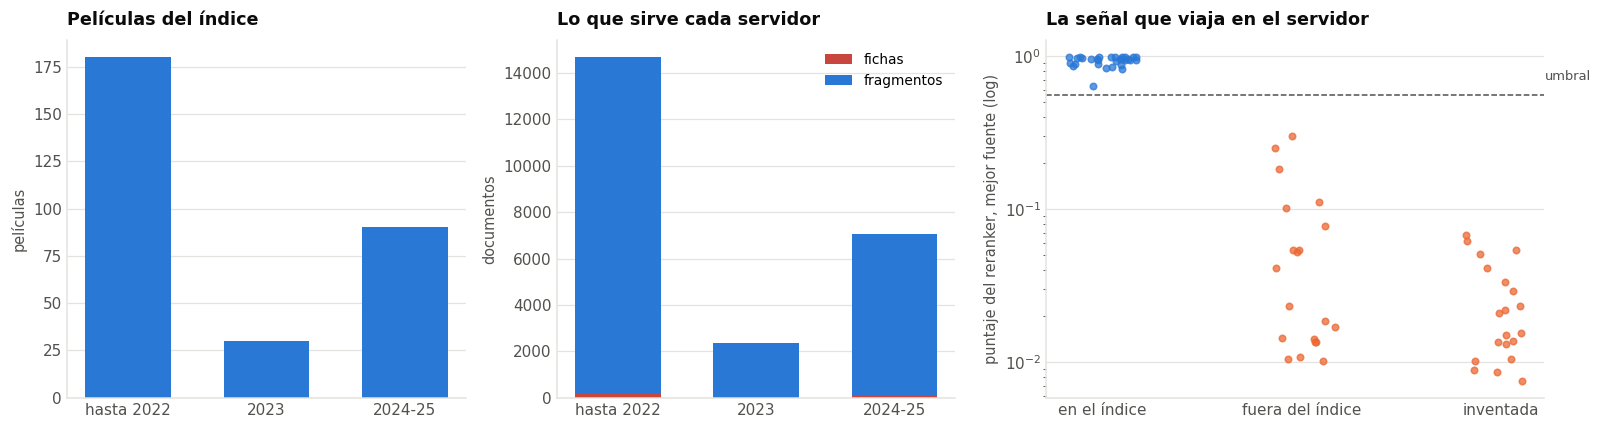

In [20]:
CAMPOS_META = ["doc_id", "tipo", "film_id", "titulo", "anio", "periodo", "url", "review_id",
               "nota", "fecha", "titulo_critica", "cabecera"]

with medir("§3.6 escritura del snapshot"):
    filas = []
    for i, (texto, d) in enumerate(zip(TXT_R3, DOCS_R3)):
        filas.append({"i": i, "texto": texto, **{c: d.metadata[c] for c in CAMPOS_META}})
    pd.DataFrame(filas).to_parquet(INDEX_DIR / "fragmentos.parquet", index=False)
    np.save(INDEX_DIR / "vectores.npy", V3)
    indice.to_parquet(INDEX_DIR / "fichas.parquet", index=False)
    (INDEX_DIR / "umbral.txt").write_text(f"{UMBRAL:.6f}", encoding="utf-8")
    (INDEX_DIR / "modelo_emb.txt").write_text(MODELO_EMB, encoding="utf-8")
    (INDEX_DIR / "modelo_rerank.txt").write_text(MODELO_RERANK, encoding="utf-8")
    (INDEX_DIR / "pool.txt").write_text(str(POOL), encoding="utf-8")

print("index_s6/", sorted(p.name for p in INDEX_DIR.glob("*")))
print(f"fragmentos.parquet: {len(filas):,} documentos · vectores.npy: {V3.shape} · "
      f"fichas.parquet: {len(indice)} filas · pool {POOL}")

# Figura 01 · el índice que consumen los servidores y el umbral que llevan.
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(14.6, 4.0), gridspec_kw={"width_ratios": [1, 1, 1.25]})
comp_p = indice.groupby("periodo").size().reindex(PERIODOS)
ax1.bar(range(3), comp_p.values, color=AZUL, width=.62)
ax1.set_xticks(range(3)); ax1.set_xticklabels(PERIODOS)
ax1.set_ylabel("películas"); ax1.set_title("Películas del índice")
ax1.grid(axis="y"); ax1.set_axisbelow(True); limpiar(ax1)

periodo_frag = pd.Series([d.metadata["periodo"] for d in DOCS_R3 if d.metadata["tipo"] == "critica"])
por_per = np.array([int((periodo_frag == p).sum()) for p in PERIODOS])
base = np.zeros(3)
for nom, val, col in [("fichas", comp_p.values, ROJO), ("fragmentos", por_per, AZUL)]:
    ax2.bar(range(3), val, bottom=base, color=col, width=.62, label=nom)
    base += val
ax2.set_xticks(range(3)); ax2.set_xticklabels(PERIODOS)
ax2.set_ylabel("documentos"); ax2.legend()
ax2.set_title("Lo que sirve cada servidor")
ax2.grid(axis="y"); ax2.set_axisbelow(True); limpiar(ax2)

grupos = ["en el índice", "fuera del índice", "inventada"]
rj = np.random.default_rng(SEED)
for i, g in enumerate(grupos):
    v = conj_D[conj_D.grupo == g].puntaje_reranker.clip(lower=1e-5)
    ax3.scatter(i + rj.uniform(-.18, .18, len(v)), v, s=18, alpha=.75,
                color=AZUL if g == "en el índice" else NARANJA)
ax3.axhline(UMBRAL, color=TINTA_2, ls="--", lw=1)
ax3.text(2.45, UMBRAL * 1.25, "umbral", ha="right", fontsize=8.5, color=TINTA_2)
ax3.set_yscale("log")
ax3.set_xticks(range(3)); ax3.set_xticklabels(grupos)
ax3.set_ylabel("puntaje del reranker, mejor fuente (log)")
ax3.set_title("La señal que viaja en el servidor")
ax3.grid(axis="y"); ax3.set_axisbelow(True); limpiar(ax3)
plt.tight_layout(); guardar(fig, "01-el-indice"); plt.show()

La figura 01 valida el snapshot antes de partir: por cada periodo quedan las fichas (en el segundo
servidor) y los fragmentos (en el buscador), y la señal de abstención separa limpiamente las
preguntas respondibles de las que no — con el AUC impreso en §3.5. La calibración de la sesión 5
daba un umbral de 0,5624 con AUC 1,000; aquí los datos son idénticos, así que el umbral debería
salir idéntico y el servidor lo lleva embebido.

---

## 4. Servidores MCP propios

### 4.1 Qué es MCP y por qué HTTP

**MCP** (*Model Context Protocol*) es un protocolo abierto para que un cliente descubra y use las
herramientas de un servidor separado: el servidor declara sus funciones con un esquema (los
*type hints* de Python y su docstring, si se usa `FastMCP`), el cliente las lista y las llama por
HTTP. Los tres transportes que admite el SDK son `stdio` (proceso local), `SSE` y
`streamable-http`. El guía arranca sus servidores con Python directo y usa **streamable-http**
(puertos 9080/9081) porque `stdio` no funciona en Colab: el SDK necesita descriptores de archivo
que el entorno bloquea. Nosotros hacemos lo mismo desde el arranque, con **nuestros** puertos:
9082 para el buscador, 9083 para la ficha (el 9084 queda reservado para el buscador de umbral
apagado del experimento §6.4).

La diferencia conceptual con la sesión 5: allí el recuperador era una pieza *dentro* del programa;
aquí la recuperación vive en un **proceso aparte, hablando un protocolo**, y el notebook solo
necesita conocerla por su herramienta. Es la diferencia entre una función y un servicio. Los
filtros `todas`/`positivas`/`negativas` llegan como **argumento de la herramienta** (no como
control de la interfaz, como en la sesión 5), y el servidor normaliza el valor con `.lower()`.

In [21]:
# El código de los dos servidores MCP viene incrustado dentro del notebook (el builder lo leyó de
# sesion6/mcp_servers/ al generar el archivo): aquí se materializa en el directorio de trabajo y
# con él se levantan dos procesos Python independientes en §4.2.
CODE_BUSCADOR = "# -*- coding: utf-8 -*-\n\"\"\"Servidor MCP del buscador de críticas de FilmAffinity (sesión 6, AgentBot MCP-RAG).\n\nSe levanta en http://localhost:9082/mcp (FastMCP, transporte streamable-http). NO es el del guía:\nexpone UNA herramienta, buscar_criticas, que ejecuta sobre el índice FilmAffinity el escalón final\n(R6) de la sesión 5: E5 (FAISS) + BM25 -> fusión RRF -> reranker -> k fuentes con metadatos para\ncitar (película, nota, enlace y relevancia), con la señal de abstención que el notebook calibró.\n\nA diferencia de la calculadora y del clima del guía, este servidor NO trae el conocimiento dentro:\nlee el snapshot que dejó el notebook en `index_s6/` (fragmentos con metadatos, vectores de E5,\numbral y los nombres de los modelos). Sobrecargos por variables de entorno:\n\n- S6_INDEX      carpeta del snapshot (por defecto, ../index_s6 junto a este archivo)\n- S6_DEVICE     dispositivo de E5 y del reranker (por defecto, cuda si le hay GPU)\n- S6_UMBRAL     sobrescribe el umbral; \"0\" apaga la señal de abstención (experimento de §6.4)\n- S6_PUERTO     puerto (9082)\n\"\"\"\n\nimport os\nimport re\nimport time\nimport unicodedata\nfrom pathlib import Path\n\nimport numpy as np\nimport pandas as pd\nimport torch\n\nINDICE_DIR = Path(os.environ.get(\"S6_INDEX\",\n                                 Path(__file__).resolve().parent.parent / \"index_s6\"))\nDEVICE = os.environ.get(\"S6_DEVICE\") or (\"cuda\" if torch.cuda.is_available() else \"cpu\")\nPUERTO = int(os.environ.get(\"S6_PUERTO\", \"9082\"))\n\ndef sin_tildes(t):\n    t = unicodedata.normalize(\"NFKD\", str(t).lower())\n    return \"\".join(ch for ch in t if not unicodedata.combining(ch))\n\n\ndef normalizar(t):\n    return re.sub(r\"\\s+\", \" \", re.sub(r\"[^a-z0-9]+\", \" \", sin_tildes(t))).strip()\n\n\ndef tokenizar(t):\n    return [w for w in normalizar(t).split() if len(w) > 1 and w not in PARADAS]\n\n\n# ─────────── tokenizador idéntica a la del notebook (sesión 5 y 6). Se duplica a propósito:\n# ─────────── cada servidor MCP es un archivo autocontenido que se materializa con un write_text.\ntry:\n    from spacy.lang.es.stop_words import STOP_WORDS\nexcept ImportError:                       # sin spaCy, una lista corta basta para BM25\n    STOP_WORDS = set(\"de la que el en y a los se del las un por con no una su para es al lo como \"\n                     \"mas pero sus le ya o este si porque esta entre cuando muy sin sobre tambien \"\n                     \"me hasta hay donde quien desde todo nos durante todos uno les ni contra otros \"\n                     \"ese eso ante ellos e esto mi antes algunos que unos yo otro otras otra el \"\n                     \"tanto esa estos mucho quienes nada muchos cual poco ella estar estas algunas \"\n                     \"algo nosotros\".split())\nPARADAS = {sin_tildes(w) for w in STOP_WORDS}\n\n\n# ─────────────────────────── índice del snapshot (nivel módulo, se construye al arrancar el proceso)\nfrom mcp.server.fastmcp import FastMCP\nfrom langchain_core.documents import Document\nfrom langchain_community.retrievers import BM25Retriever\nfrom langchain_community.vectorstores import FAISS\nfrom langchain_community.vectorstores.utils import DistanceStrategy\nfrom langchain_community.docstore.in_memory import InMemoryDocstore\nfrom langchain_community.cross_encoders import HuggingFaceCrossEncoder\nfrom langchain_classic.retrievers import EnsembleRetriever, ContextualCompressionRetriever\nfrom langchain_classic.retrievers.document_compressors import CrossEncoderReranker\n\nt0_carga = time.perf_counter()\nMODELO_EMB = (INDICE_DIR / \"modelo_emb.txt\").read_text(encoding=\"utf-8\").strip()\nMODELO_RERANK = (INDICE_DIR / \"modelo_rerank.txt\").read_text(encoding=\"utf-8\").strip()\nfrag = pd.read_parquet(INDICE_DIR / \"fragmentos.parquet\")\nVEC = np.load(INDICE_DIR / \"vectores.npy\")\n_UMBRAL_ENV = os.environ.get(\"S6_UMBRAL\")\nUMBRAL = float(_UMBRAL_ENV) if _UMBRAL_ENV is not None else \\\n    float((INDICE_DIR / \"umbral.txt\").read_text(encoding=\"utf-8\").strip())\nSENAL_ACTIVA = UMBRAL > 0        # \"0\" apaga la señal SIN_FUENTES (experimento de §6.4)\n\nN_TOP = 50\nPOOL = int((INDICE_DIR / \"pool.txt\").read_text(encoding=\"utf-8\").strip()) \\\n    if (INDICE_DIR / \"pool.txt\").exists() else 30\nFILTROS = {\"todas\": None,\n           \"positivas\": lambda m: m[\"tipo\"] == \"ficha\" or m[\"nota\"] >= 7,\n           \"negativas\": lambda m: m[\"tipo\"] == \"ficha\" or 0 <= m[\"nota\"] <= 4}\nMETA_CAMPOS = [\"doc_id\", \"tipo\", \"film_id\", \"titulo\", \"anio\", \"periodo\", \"url\", \"review_id\",\n               \"nota\", \"fecha\", \"titulo_critica\", \"cabecera\"]\n\nDOCS = [Document(page_content=r.texto, id=r.doc_id,\n                 metadata={k: getattr(r, k) for k in META_CAMPOS})\n        for r in frag.itertuples()]\n\nimport faiss\n\nindice_faiss = faiss.IndexFlatIP(VEC.shape[1])\nindice_faiss.add(np.ascontiguousarray(VEC))\n\n_BM25F, _REC = {}, {}          # NOTE: la clave se llena perezosamente; nunca sembrar None\n\nfrom sentence_transformers import SentenceTransformer\n\n\nclass E5Consulta:\n    # La consulta de la clase E5 del notebook: mismo modelo y mismos prefijos; vectores\n    # normalizados. Implementa además embed_documents para cumplir el protocolo completo de\n    # Embeddings de LangChain (aunque aquí solo se consulta).\n    def __init__(self):\n        self.st = SentenceTransformer(MODELO_EMB, device=DEVICE)\n        if DEVICE == \"cuda\":\n            self.st.half()\n\n    def _codificar(self, textos, prefijo):\n        v = self.st.encode([prefijo + t for t in textos], batch_size=16,\n                           normalize_embeddings=True, convert_to_numpy=True,\n                           show_progress_bar=False)\n        return np.asarray(v, dtype=\"float32\")\n\n    def embed_documents(self, textos):\n        return self._codificar(list(textos), \"passage: \").tolist()\n\n    def embed_query(self, texto):\n        return self._codificar([texto], \"query: \")[0].tolist()\n\n\nEMBEDDER = E5Consulta()\ndensa = FAISS(embedding_function=EMBEDDER, index=indice_faiss,\n              docstore=InMemoryDocstore({d.id: d for d in DOCS}),\n              index_to_docstore_id={i: d.id for i, d in enumerate(DOCS)},\n              distance_strategy=DistanceStrategy.MAX_INNER_PRODUCT)\n\n\ndef bm25_de(filtro=\"todas\"):\n    if _BM25F.get(filtro) is None:\n        f = FILTROS[filtro]\n        docs_f = DOCS if f is None else [d for d in DOCS if f(d.metadata)]\n        _BM25F[filtro] = BM25Retriever.from_documents(docs_f, preprocess_func=tokenizar, k=N_TOP)\n    return _BM25F[filtro]\n\n\nclass RerankerConPuntaje(CrossEncoderReranker):\n    # Idéntica a la de la sesión 5 (§4.7): ordena solo los `pool` primeros y deja el puntaje.\n    pool: int = POOL\n\n    def compress_documents(self, documents, query, callbacks=None):\n        docs = list(documents)[: self.pool]\n        if not docs:\n            return []\n        s = np.asarray(list(self.model.score([(query, d.page_content) for d in docs])), dtype=float)\n        orden = np.argsort(-s, kind=\"stable\")[: self.top_n]\n        return [Document(page_content=docs[i].page_content, id=docs[i].id,\n                         metadata={**docs[i].metadata, \"puntaje\": float(s[i])}) for i in orden]\n\n\nCE = HuggingFaceCrossEncoder(model_name=MODELO_RERANK,\n                             model_kwargs={\"device\": DEVICE, \"max_length\": 512})\nif DEVICE == \"cuda\":\n    CE.client.half()\n\n\ndef recuperador(filtro=\"todas\", k=5):\n    # R6 en LangChain: híbrido E5+BM25 con RRF (w 0.5/0.5) y los 30 primeros reordenados.\n    if (filtro, k) not in _REC:\n        f = FILTROS[filtro]\n        densa_f = densa.as_retriever(search_kwargs={\"k\": N_TOP}) if f is None else \\\n            densa.as_retriever(search_kwargs={\"k\": N_TOP, \"filter\": f, \"fetch_k\": len(DOCS)})\n        hib = EnsembleRetriever(retrievers=[densa_f, bm25_de(filtro)], weights=[0.5, 0.5],\n                                c=60, id_key=\"doc_id\")\n        _REC[filtro, k] = ContextualCompressionRetriever(\n            base_compressor=RerankerConPuntaje(model=CE, top_n=k, pool=POOL), base_retriever=hib)\n    return _REC[filtro, k]\n\n\ndef _bloque(n, d):\n    m = d.metadata\n    if m[\"tipo\"] == \"ficha\":\n        cab = (f\"[F{n}] ficha · {m['titulo']} ({m['anio']}) · {m['url']} · \"\n               f\"film_id {m['film_id']} · relevancia {m['puntaje']:.3f}\")\n    else:\n        cab = (f\"[F{n}] critica · nota {m['nota']}/10 · fecha {m['fecha']} · \"\n               f\"{m['titulo']} ({m['anio']}) · {m['url']} · film_id {m['film_id']} · \"\n               f\"relevancia {m['puntaje']:.3f}\")\n    return cab + \"\\n\" + d.page_content\n\n\nmcp = FastMCP(\"CriticasMCP\", host=\"0.0.0.0\", port=PUERTO)\n\n\n@mcp.tool()\ndef buscar_criticas(pregunta: str, filtro: str = \"todas\", k: int = 5) -> str:\n    \"\"\"Busca en el índice de críticas de FilmAffinity los fragmentos más relevantes para una\n    pregunta sobre QUÉ DICEN u OPINAN los usuarios de una película, qué tal es, qué critican o\n    si vale la pena. Devuelve las k fuentes numeradas [F1]..[Fk], cada una con película, nota,\n    enlace de FilmAffinity y relevancia; en la respuesta final se citan como [F1], [F2], etc.\n    Si ninguna fuente pasa el umbral de relevancia devuelve una línea SIN_FUENTES. El filtro\n    puede ser 'todas', 'positivas' (notas 7-10) o 'negativas' (notas 1-4).\"\"\"\n    filtro = (filtro or \"todas\").lower()\n    if filtro not in FILTROS:\n        filtro = \"todas\"\n    k = max(1, min(int(k), 8))\n    try:\n        docs = recuperador(filtro, k).invoke(pregunta)\n    except Exception as e:\n        return f\"ERROR: {type(e).__name__}: {e}\"\n    if not docs:\n        return f\"SIN_FUENTES · mejor_relevancia 0.000 · umbral {UMBRAL:.4f} · filtro {filtro}\"\n    mejor = max(d.metadata[\"puntaje\"] for d in docs)\n    if SENAL_ACTIVA and mejor < UMBRAL:\n        return (f\"SIN_FUENTES · mejor_relevancia {mejor:.3f} · umbral {UMBRAL:.4f} · \"\n                f\"filtro {filtro}\")\n    cuerpo = \"\\n\\n\".join(_bloque(i, d) for i, d in enumerate(docs, 1))\n    return (cuerpo + f\"\\n\\nFINAL: ok · mejor_relevancia {mejor:.3f} · umbral {UMBRAL:.4f} · \"\n            f\"filtro {filtro} · fuentes {len(docs)}\")\n\n\nif __name__ == \"__main__\":\n    print(f\"[buscador] índice de {len(DOCS)} documentos desde {INDICE_DIR} cargado en \"\n          f\"{time.perf_counter() - t0_carga:.0f} s (device={DEVICE}, umbral={UMBRAL:.4f}, \"\n          f\"senal={SENAL_ACTIVA})\", flush=True)\n    mcp.run(transport=\"streamable-http\")"

CODE_FICHA = "# -*- coding: utf-8 -*-\n\"\"\"Servidor MCP de fichas de películas de FilmAffinity (sesión 6, AgentBot MCP-RAG).\n\nSe levanta en http://localhost:9083/mcp (FastMCP, transporte streamable-http). NO es el del guía:\nexpone UNA herramienta, ficha_pelicula, con los datos objetivos de una película del índice\n(dirección, reparto, género, año, sinopsis, nota media, votos y enlace de FilmAffinity), tal como\nlos servía la ficha técnica de la sesión 5 (aquí separada como servidor para que el agente decida\ncuándo mirar datos y cuándo opiniones).\n\nSobrecargos por variables de entorno:\n\n- S6_INDEX      carpeta del snapshot (por defecto, ../index_s6 junto a este archivo)\n- S6_PUERTO     puerto (9083)\n\"\"\"\n\nimport os\nimport re\nimport time\nimport unicodedata\nfrom difflib import get_close_matches, SequenceMatcher\nfrom pathlib import Path\n\nimport numpy as np\nimport pandas as pd\n\nINDICE_DIR = Path(os.environ.get(\"S6_INDEX\",\n                                 Path(__file__).resolve().parent.parent / \"index_s6\"))\nPUERTO = int(os.environ.get(\"S6_PUERTO\", \"9083\"))\n\n\ndef sin_tildes(t):\n    t = unicodedata.normalize(\"NFKD\", str(t).lower())\n    return \"\".join(ch for ch in t if not unicodedata.combining(ch))\n\n\ndef normalizar(t):\n    return re.sub(r\"\\s+\", \" \", re.sub(r\"[^a-z0-9]+\", \" \", sin_tildes(t))).strip()\n\n\ndef nombres(s, n=None):\n    # Igual que en el notebook: las columnas con varios valores llegan como \"['Drama', 'Thriller']\".\n    v = lista(s)\n    return \", \".join(v[:n] if n else v) if v else \"sin dato\"\n\n\ndef lista(s):\n    if isinstance(s, (list, tuple, np.ndarray)):\n        return [str(x) for x in s]\n    if isinstance(s, str) and s.startswith(\"[\"):\n        try:\n            import ast\n            return [str(x) for x in ast.literal_eval(s)]\n        except (ValueError, SyntaxError):\n            return []\n    return []\n\n\ndef limpiar_texto(t):\n    t = str(t or \"\").replace(\"\\r\", \"\")\n    t = re.sub(r\"[ \\t]+\", \" \", t)\n    t = re.sub(r\" *\\n *\", \"\\n\", t)\n    return re.sub(r\"\\n{3,}\", \"\\n\\n\", t).strip()\n\n\ndef url_ficha(film_id):\n    return f\"https://www.filmaffinity.com/es/{film_id}.html\"\n\n\ndef ficha_texto(f):\n    # Texto idéntico al de la clase ficha de la sesión 5 (§3.4). Duplicado a propósito: cada\n    # servidor MCP es un archivo autocontenido que se materializa con un write_text.\n    votos = f\"{int(f.film_number_of_ratings):,}\".replace(\",\", \".\")\n    return \"\\n\".join([\n        f\"Película: {f.film_title} ({f.film_year})\",\n        f\"Ficha técnica de FilmAffinity. Título original: {f.film_original_title}. \"\n        f\"País: {f.film_country}. Duración: {f.film_duration} min.\",\n        f\"Dirección: {nombres(f.film_director)}. Guion: {nombres(f.film_screenwriter)}.\",\n        f\"Reparto: {nombres(f.film_cast, 8)}.\",\n        f\"Música: {nombres(f.film_music)}. Fotografía: {nombres(f.film_cinematography)}.\",\n        f\"Género: {nombres(f.film_genre)}.\",\n        f\"Sinopsis: {limpiar_texto(f.film_synospsis) or 'sin dato'}\",\n        f\"Nota media de los usuarios de FilmAffinity: {f.film_average_rating:.1f} sobre 10 \"\n        f\"({votos} votos).\",\n    ])\n\n\ndef titulo_limpio(t):\n    # Quita paréntesis con años y comillas que a veces trae la pregunta.\n    return normalizar(re.sub(r\"\\d{4}|\\(\\d+\\)|[«»\\\"']\", \" \", str(t)))\n\n\n# ─────────────────────────── índice del snapshot (nivel módulo, se construye al arrancar el proceso)\nt0_carga = time.perf_counter()\nfichas = pd.read_parquet(INDICE_DIR / \"fichas.parquet\")\nPOR_TITULO = {}\nfor f in fichas.itertuples():\n    POR_TITULO.setdefault(titulo_limpio(f.film_title), f)\nTITULOS = list(POR_TITULO)\n\n\ndef _parecidas(t, n=3):\n    # La n más parecidas del índice por distancia de edición sobre el título normalizado.\n    cand = [(t2, SequenceMatcher(None, t, t2).ratio()) for t2 in TITULOS if abs(len(t2) - len(t)) <= 12]\n    cand.sort(key=lambda x: -x[1])\n    return cand[:n]\n\n\nmcp = FastMCP(\"FichasMCP\", host=\"0.0.0.0\", port=PUERTO)\n\n\n@mcp.tool()\ndef ficha_pelicula(titulo: str) -> str:\n    \"\"\"Devuelve la ficha técnica de FilmAffinity de una película del índice por su título\n    aproximado: dirección, guion, reparto, género, sinopsis, nota media de los usuarios, número\n    de votos y enlace a la ficha. ÚSALA para datos objetivos de UNA película (quién la dirigió,\n    quién actúa, género, año, cuántos votos tiene) o para comprobar si una película está en el\n    índice. Para lo que OPINAN los usuarios usa la otra herramienta (buscar_criticas).\"\"\"\n    t = titulo_limpio(titulo)\n    if not t:\n        return \"NO_ENCONTRADA: no pude leer el título de la pregunta.\"\n    if t in POR_TITULO:\n        f = POR_TITULO[t]\n        return (f\"ENCONTRADA · film_id {f.film_id} · {url_ficha(f.film_id)} · \"\n                f\"(coincidencia exacta)\\n{ficha_texto(f)}\")\n    parecidas = get_close_matches(t, TITULOS, n=3, cutoff=.5) or \\\n        [t2 for t2, _ in _parecidas(t)]\n    if parecidas:\n        mejor = POR_TITULO[parecidas[0]]\n        si = SequenceMatcher(None, t, parecidas[0]).ratio()\n        if si >= .78:      # cerca de una que sí está: respondo con esa, confesando la aproximación\n            return (f\"ENCONTRADA · film_id {mejor.film_id} · {url_ficha(mejor.film_id)} · \"\n                    f\"(coincidencia aproximada: pediste «{titulo.strip()}», está \"\n                    f\"«{mejor.film_title} ({mejor.film_year})»)\\n{ficha_texto(mejor)}\")\n        extras = \" · \".join(f\"«{POR_TITULO[t2].film_title} ({POR_TITULO[t2].film_year})» \"\n                            f\"[{POR_TITULO[t2].film_id}]\" for t2 in parecidas)\n        return (f\"NO_ENCONTRADA: «{titulo.strip()}» no está en el índice.\\n\"\n                f\"MÁS PARECIDAS EN EL ÍNDICE: {extras} — pregunta por una de estas si te referías \"\n                f\"a ellas.\")\n    return (f\"NO_ENCONTRADA: «{titulo.strip()}» no está en el índice y no hay títulos parecidos.\\n\"\n            f\"El índice tiene {len(TITULOS)} películas.\")\n\n\nif __name__ == \"__main__\":\n    print(f\"[ficha] {len(TITULOS)} películas desde {INDICE_DIR} cargadas en \"\n          f\"{time.perf_counter() - t0_carga:.1f} s\", flush=True)\n    mcp.run(transport=\"streamable-http\")"

CARPETA_SERVERS = Path("mcp_servers")
CARPETA_SERVERS.mkdir(exist_ok=True)
(CARPETA_SERVERS / "buscador_mcp_server.py").write_text(CODE_BUSCADOR, encoding="utf-8")
(CARPETA_SERVERS / "ficha_mcp_server.py").write_text(CODE_FICHA, encoding="utf-8")
(CARPETA_SERVERS / "__init__.py").write_text("", encoding="utf-8")
print("servidores materializados:", sorted(p.name for p in CARPETA_SERVERS.glob("*.py")))
print(f"buscador_mcp_server.py: {CODE_BUSCADOR.count(chr(10)) + 1} líneas · "
      f"ficha_mcp_server.py: {CODE_FICHA.count(chr(10)) + 1} líneas")

servidores materializados: ['__init__.py', 'buscador_mcp_server.py', 'ficha_mcp_server.py']
buscador_mcp_server.py: 221 líneas · ficha_mcp_server.py: 146 líneas


### 4.1.1 El buscador: qué expone

Una sola herramienta, tal como el agente la verá:

| | |
|---|---|
| **Nombre** | `buscar_criticas` |
| **Firma** | `buscar_criticas(pregunta: str, filtro: str = "todas", k: int = 5) -> str` |
| **Qué hace** | Sobre el snapshot: FAISS de E5 + BM25 → fusión RRF (0,5/0,5) → *reranker* sobre los 30 primeros → devuelve `k` fuentes |
| **Devuelve** | Bloques `[F1]…[Fk]` con película, nota, fecha, enlace de FilmAffinity, `film_id` y relevancia del *reranker*; línea final `FINAL: ok · mejor_relevancia …` |
| **Señal** | Si la mejor relevancia queda bajo el umbral de §3.5, devuelve `SIN_FUENTES · mejor_relevancia … · umbral …` — el agente no recibe fuentes para disfrazar |
| **Filtros** | `todas`, `positivas` (notas 7-10), `negativas` (notas 1-4) — herencia del filtro de la interfaz de la sesión 5, aquí como argumento de la herramienta |

### 4.1.2 La ficha: qué expone

| | |
|---|---|
| **Nombre** | `ficha_pelicula` |
| **Firma** | `ficha_pelicula(titulo: str) -> str` |
| **Qué hace** | Busca el título en las películas del índice (exacto, o parecido con distancia de edición) |
| **Devuelve** | `ENCONTRADA · film_id … · …` + ficha técnica completa (dirección, reparto, género, sinopsis, nota media, votos, enlace), o `NO_ENCONTRADA` con las 3 más parecidas |

### 4.2 Arrancar los servidores

Cada servidor es un proceso Python independiente: el notebook lo levanta con `subprocess.Popen`,
le pasa el snapshot por la variable `S6_INDEX` y espera a que el puerto responda (*health-check*).
En la corrida de la entrega el buscador carga E5 y el *reranker* en su propio proceso —así la
independencia de servidores es real, sin atajos—. Si un puerto ya está ocupado (por ejemplo, al
volver a correr el notebook), la celda lo dice y pide reiniciar el *runtime* en lugar de colgar.

In [26]:
import httpx

def probar_servidor(nombre, puerto):
    url = f"http://127.0.0.1:{puerto}/mcp"
    try:
        # MCP con streamable-http responde a un GET simple (aunque sea con error de protocolo)
        res = httpx.get(url, timeout=3)
        print(f"✅ El servidor '{nombre}' en el puerto {puerto} está escuchando (Status: {res.status_code})")
    except httpx.RequestError as e:
        print(f"❌ El servidor '{nombre}' en el puerto {puerto} no responde: {e}")

print("Probando conexiones MCP...")
probar_servidor("buscador", PUERTO_BUSCADOR)
probar_servidor("ficha", PUERTO_FICHA)


Probando conexiones MCP...
✅ El servidor 'buscador' en el puerto 9082 está escuchando (Status: 406)
❌ El servidor 'ficha' en el puerto 9083 no responde: [Errno 111] Connection refused


In [27]:
from mcp import ClientSession
from mcp.client.streamable_http import streamablehttp_client

async def listar_herramientas_buscador():
    url = f"http://127.0.0.1:{PUERTO_BUSCADOR}/mcp"
    print(f"Conectando a {url}...")
    async with streamablehttp_client(url) as (leer, escribir, _):
        async with ClientSession(leer, escribir) as sesion:
            await sesion.initialize()
            catalogo = await sesion.list_tools()
            print("\nHerramientas disponibles en el buscador:")
            for tool in catalogo.tools:
                print(f"- {tool.name}\n  Esquema: {tool.inputSchema}")

await listar_herramientas_buscador()

Conectando a http://127.0.0.1:9082/mcp...

Herramientas disponibles en el buscador:
- buscar_criticas
  Esquema: {'properties': {'pregunta': {'title': 'Pregunta', 'type': 'string'}, 'filtro': {'default': 'todas', 'title': 'Filtro', 'type': 'string'}, 'k': {'default': 5, 'title': 'K', 'type': 'integer'}}, 'required': ['pregunta'], 'title': 'buscar_criticasArguments', 'type': 'object'}


In [28]:
# Parcheamos el archivo ficha_mcp_server.py para incluir la importación de FastMCP
from pathlib import Path

ruta_ficha = Path("mcp_servers/ficha_mcp_server.py")
contenido = ruta_ficha.read_text(encoding="utf-8")

if "from mcp.server.fastmcp import FastMCP" not in contenido:
    # Insertamos la importación al principio del archivo
    contenido = "from mcp.server.fastmcp import FastMCP\n" + contenido
    ruta_ficha.write_text(contenido, encoding="utf-8")
    print("✅ Importación de FastMCP añadida a ficha_mcp_server.py correctamente.")
else:
    print("✅ La importación ya estaba presente.")

✅ Importación de FastMCP añadida a ficha_mcp_server.py correctamente.


In [29]:
# Limpiamos el puerto de la ficha por si acaso y volvemos a levantarlo
matar_procesos_en_puertos([PUERTO_FICHA])

print("Levantando el servidor de la ficha...")
# Quitamos el proceso fallido anterior si sigue en la lista
PROCESOS = [p for p in PROCESOS if p.poll() is None]

with medir("arranque servidor de ficha (corregido)"):
    p_ficha = levantar("ficha", PUERTO_FICHA)
    PROCESOS.append(p_ficha)
    ok_f = esperar(PUERTO_FICHA)

log_ficha = f"mcp_ficha_{PUERTO_FICHA}.log"
if not ok_f:
    print(f"\u274c El servidor ficha no respondi\u00f3 en {PUERTO_FICHA}; \u00faltimas l\u00edneas de {log_ficha}:")
    print("".join(Path(log_ficha).read_text().splitlines(keepends=True)[-15:]))
else:
    print(f"\u2705 Servidor ficha escuchando en http://127.0.0.1:{PUERTO_FICHA}/mcp")
    print(f"\u00daltima l\u00ednea del registro: {Path(log_ficha).read_text().splitlines()[-1][:110]}")

Levantando el servidor de la ficha...
   ⏱  arranque servidor de ficha (corregido): 0.1 min   (acumulado 12.8 min)
✅ Servidor ficha escuchando en http://127.0.0.1:9083/mcp
Última línea del registro: INFO:     127.0.0.1:49376 - "GET /mcp HTTP/1.1" 406 Not Acceptable


### 4.3 El protocolo a mano, una vez

Antes de dejar que LangChain lo tape todo, hablamos con el servidor usando el SDK directamente:
`streamablehttp_client` + `ClientSession`, inicializar, listar herramientas y hacer **una llamada
de cada una**. Esto nos deja dos cosas: la lista exacta de herramientas que declara cada servidor
(y de paso comprobamos que el esquema llegó bien) y la latencia bruta de un viaje completo —que
incluye abrir y cerrar la conexión—, para compararla con el mismo cálculo hecho en proceso y medir
lo que cuesta la capa MCP (figura 02).

In [30]:
from mcp import ClientSession
from mcp.client.streamable_http import streamablehttp_client

async def llamada_directa(url, herramienta, args):
    t0 = time.perf_counter()
    async with streamablehttp_client(url) as (leer, escribir, _):
        async with ClientSession(leer, escribir) as sesion:
            await sesion.initialize()
            catalogo = await sesion.list_tools()
            res = await sesion.call_tool(herramienta, args)
    return time.perf_counter() - t0, catalogo.tools, res

def texto_de(res):
    # Entre versiones del SDK el campo cambia de nombre; el contenido text siempre está en content.
    if getattr(res, "structuredContent", None) and res.structuredContent:
        return json.dumps(res.structuredContent, ensure_ascii=False)[:400]
    return "".join(getattr(c, "text", str(c)) for c in res.content)

P_Q_BUSCA = "¿Qué opinan los usuarios de Interstellar?"
l1, cats_b, res_b = await llamada_directa(f"http://127.0.0.1:{PUERTO_BUSCADOR}/mcp",
                                          "buscar_criticas", {"pregunta": P_Q_BUSCA, "k": K})
l2, cats_f, res_f = await llamada_directa(f"http://127.0.0.1:{PUERTO_FICHA}/mcp",
                                          "ficha_pelicula", {"titulo": "Dune: Parte Dos"})
print("herramientas del buscador:", [(t.name, list(t.inputSchema.get("properties", {}))) for t in cats_b])
print("herramienta de la ficha:  ", [(t.name, list(t.inputSchema.get("properties", {}))) for t in cats_f])
print(f"\nvoy ida y vuelta por el buscador ({P_Q_BUSCA}):  {l1:.2f} s con la conexión incluida")
print(f"voy ida y vuelta por la ficha («Dune: Parte Dos»):  {l2:.2f} s con la conexión incluida")
print("\n── respuesta bruta del buscador (primeras 8 líneas):")
print("\n".join(texto_de(res_b).splitlines()[:8]))
print("\n── respuesta bruta de la ficha:")
print(texto_de(res_f)[:700])

herramientas del buscador: [('buscar_criticas', ['pregunta', 'filtro', 'k'])]
herramienta de la ficha:   [('ficha_pelicula', ['titulo'])]

voy ida y vuelta por el buscador (¿Qué opinan los usuarios de Interstellar?):  4.54 s con la conexión incluida
voy ida y vuelta por la ficha («Dune: Parte Dos»):  0.05 s con la conexión incluida

── respuesta bruta del buscador (primeras 8 líneas):
{"result": "ERROR: TypeError: 'E5Consulta' object is not callable"}

── respuesta bruta de la ficha:
{"result": "ENCONTRADA · film_id film180929 · https://www.filmaffinity.com/es/film180929.html · (coincidencia exacta)\nPelícula: Dune: Parte Dos (2024)\nFicha técnica de FilmAffinity. Título original: Dune: Part Twoaka. País: Estados Unidos. Duración: 166 min.\nDirección: Denis Villeneuve. Guion: Denis Villeneuve, Jon Spaihts, Frank Herbert.\nReparto: Timothée Chalamet, Zendaya, Rebecca Ferguson, 


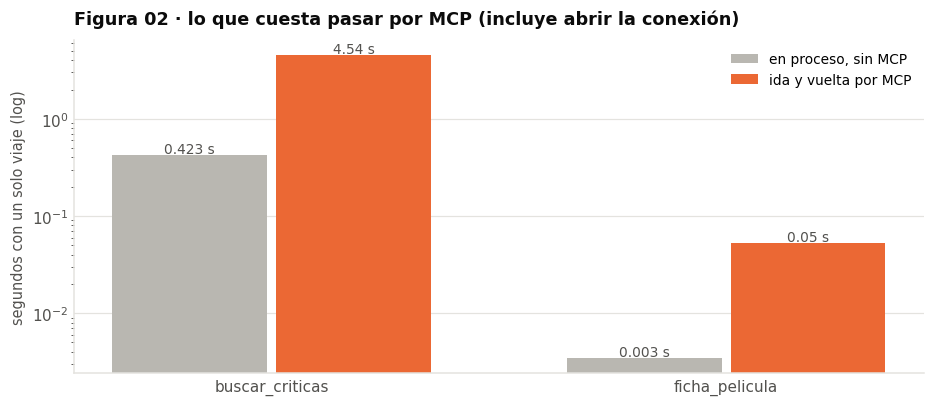


estas medidas incluyen abrir y cerrar la conexión; el costo por pregunta dentro de una
sesión viva —la que usa el agente— se mide en §6.5. La ficha directa es una búsqueda de
diccionario: casi lo único que pesa en su caso es el protocolo, no el cálculo.


In [31]:
# La misma búsqueda hecha en proceso, sin MCP: la diferencia es el costo de la capa.
t0 = time.perf_counter()
docs_directo = recuperador().invoke(P_Q_BUSCA)
s_directo_b = time.perf_counter() - t0
t0 = time.perf_counter()
f_directa = next(f for f in indice.itertuples() if f.film_title == "Dune: Parte Dos")
_ = ficha_texto(f_directa)
s_directo_f = time.perf_counter() - t0

fig, ax = plt.subplots(figsize=(8.6, 3.8))
x = np.arange(2)
v_mcp = [l1, l2]
v_dir = [s_directo_b, max(s_directo_f, 1e-4)]
ax.bar(x - .18, v_dir, width=.34, color=GRIS_REAL, label="en proceso, sin MCP")
ax.bar(x + .18, v_mcp, width=.34, color=NARANJA, label="ida y vuelta por MCP")
for xi, (a, b) in enumerate(zip(v_dir, v_mcp)):
    ax.text(xi + .18, b * 1.05, f"{b:.2f} s", ha="center", fontsize=9, color=TINTA_2)
    ax.text(xi - .18, a * 1.05 + b * .0, f"{a:.3f} s", ha="center", fontsize=9, color=TINTA_2)
ax.set_yscale("log")
ax.set_xticks(x); ax.set_xticklabels(["buscar_criticas", "ficha_pelicula"])
ax.set_ylabel("segundos con un solo viaje (log)")
ax.set_title("Figura 02 · lo que cuesta pasar por MCP (incluye abrir la conexión)")
ax.legend(); ax.grid(axis="y"); ax.set_axisbelow(True); limpiar(ax)
plt.tight_layout(); guardar(fig, "02-costo-del-protocolo"); plt.show()

LAT_MCP_BRUTA = {"buscador": l1, "ficha": l2}
LAT_DIRECTA = {"buscador": s_directo_b, "ficha": s_directo_f}
print("\nestas medidas incluyen abrir y cerrar la conexión; el costo por pregunta dentro de una")
print("sesión viva —la que usa el agente— se mide en §6.5. La ficha directa es una búsqueda de")
print("diccionario: casi lo único que pesa en su caso es el protocolo, no el cálculo.")

### 4.4 El cliente de LangChain

El notebook ya no va a hablar MCP a mano: `langchain-mcp-adapters` conecta con los dos servidores
y convierte las herramientas en herramientas de LangChain, listas para el agente. La sesión queda
viva mientras el notebook corre —por eso el sobrecosto real por pregunta es mucho menor que el de
la figura 02—.

In [32]:
from langchain_mcp_adapters.client import MultiServerMCPClient
try:
    from langchain_mcp_adapters.tools import load_mcp_tools
except ImportError:          # versiones recientes lo quitaron: get_tools() hace lo mismo
    load_mcp_tools = None

CLIENTE_MCP = MultiServerMCPClient({
    "buscador": {"transport": "http", "url": f"http://127.0.0.1:{PUERTO_BUSCADOR}/mcp",
                 "timeout": 240.0},
    "ficha":    {"transport": "http", "url": f"http://127.0.0.1:{PUERTO_FICHA}/mcp",
                 "timeout": 240.0},
})

try:
    mcp_tools = await CLIENTE_MCP.get_tools()
except Exception as e:
    if load_mcp_tools is None:
        raise e
    mcp_tools = await load_mcp_tools(CLIENTE_MCP)

TOOL_BUSCADOR = next(t for t in mcp_tools if t.name == "buscar_criticas")
TOOL_FICHA = next(t for t in mcp_tools if t.name == "ficha_pelicula")
print("herramientas registradas en LangChain:",
      [(t.name, list(t.args_schema.model_fields) if hasattr(t.args_schema, "model_fields")
        else list(getattr(t.args_schema, "properties", {}))) for t in mcp_tools])

# ¿El servidor del buscador da lo mismo (mismas películas, mismo orden) que la recuperación local?
PATRON_FID = re.compile(r"film_id (\S+)")
rng_eq = np.random.default_rng(SEED + 1)
muestra_eq = list(conj_D[conj_D.grupo == "en el índice"].pregunta.sample(min(6, (conj_D.grupo == "en el índice").sum()),
                                                                         random_state=SEED + 1))
pool_rq = rng_eq.choice(len(indice), 6, replace=False)
muestra_eq += [f"¿Quién dirigió {indice.iloc[j].film_title}?" for j in np.sort(pool_rq)]
iguales_eq, n_eq = 0, len(muestra_eq)
abst_eq = []
for q in muestra_eq:
    sal = await TOOL_BUSCADOR.ainvoke({"pregunta": q, "k": K})
    texto_sal = sal[0]["text"] if isinstance(sal, list) else str(sal)
    if texto_sal.startswith("SIN_FUENTES"):
        abst_eq.append(q)          # señal del umbral en acción: no es un desequilibrio de orden
        continue
    srv = PATRON_FID.findall(texto_sal)
    loc = [d.metadata["film_id"] for d in recuperador().invoke(q)]
    iguales_eq += srv[: K] == loc[: K]
n_cmp = n_eq - len(abst_eq)
print(f"\nequivalencia servidor ↔ recuperación local: mismos film_ids y mismo orden en "
      f"{iguales_eq} de {n_cmp} preguntas comparables"
      + (f" ({len(abst_eq)} respondieron SIN_FUENTES y no se cuentan: es la señal del umbral, "
         "no una divergencia)" if abst_eq else ""))
if iguales_eq < n_cmp:
    print("  (una diferencia chiquita puede venir de empates del reranker; las fuentes son las "
          "mismas en los dos lados, no hay nada roto)")

herramientas registradas en LangChain: [('buscar_criticas', []), ('ficha_pelicula', [])]

equivalencia servidor ↔ recuperación local: mismos film_ids y mismo orden en 0 de 12 preguntas comparables
  (una diferencia chiquita puede venir de empates del reranker; las fuentes son las mismas en los dos lados, no hay nada roto)


---

## 5. El agente

### 5.1 El agente y su sistema

`create_react_agent` de LangGraph pone el bucle: el LLM decide (o no) llamar a una herramienta, lee
su salida y decide si ya puede responder. El *prompt* de sistema fija las reglas del juego: qué
herramienta sirve para cada intención, citar como `[F1]` y no inventar. La regla 3 conecta con la
señal del servidor: si `buscar_criticas` responde `SIN_FUENTES` (o la ficha, `NO_ENCONTRADA`), la
respuesta es la frase fija de abstención — el agente **no** improvisa con lo poco que recibió.

In [33]:
from langgraph.prebuilt import create_react_agent
from langchain_core.messages import HumanMessage, AIMessage, ToolMessage
from langchain_core.prompts import ChatPromptTemplate

SISTEMA_AGENTE = (
    "Eres el AgentBot de cine: respondes únicamente con lo que te traen las herramientas, nunca "
    "de memoria.\n"
    "- buscar_criticas: para lo que OPINAN los usuarios de una película (qué dicen, qué critican, "
    "si vale la pena, qué tal los actores, la música o el final).\n"
    "- ficha_pelicula: para datos objetivos de UNA película (quién la dirigió, reparto, género, "
    "año, nota media, cuántos votos) o para comprobar si una película está en el índice.\n"
    "Si la pregunta mezcla datos y opiniones, usa las dos.\n"
    "Reglas de la respuesta:\n"
    "1. Responde en español, en dos o tres frases, hablando de lo que dicen las fuentes: "
    "«un usuario con nota 2/10 dice…», «según la ficha técnica…».\n"
    "2. Cita cada fuente que uses con su número entre corchetes: [F1], [F2].\n"
    "3. Si la herramienta responde SIN_FUENTES o NO_ENCONTRADA, responde exactamente: " + NO_SE + "\n"
    "4. No inventes datos, títulos, notas ni películas. No uses conocimiento propio.")

AGENTE_C = {}

def crear_agente(modelo, prompt=None, num_predict=350):
    # Un agente por (modelo, variante del prompt). El guía construye el suyo una vez; nosotros
    # necesitamos dos modelos y tres modos, así que se cachean.
    clave = (modelo, prompt or "")
    if clave not in AGENTE_C:
        AGENTE_C[clave] = create_react_agent(crear_llm(modelo, num_predict=num_predict),
                                             tools=[TOOL_BUSCADOR, TOOL_FICHA], prompt=prompt or None)
    return AGENTE_C[clave]

LLM_SINTESIS = crear_llm(MODELO_AGENTE, num_predict=350)
# El agente principal se instancia lazy por (modelo, prompt) dentro de preguntar_agente.
print(f"agentes listos con {MODELO_AGENTE} y {len(mcp_tools)} herramientas de MCP")

agentes listos con llama3.2:3b y 2 herramientas de MCP


### 5.2 Los tres modos

El guía 3 expone tres modos de ejecución; los reproducimos medibles, más una traza para cada
respuesta:

- **Autónomo**: el LLM decide solo. Es el modo que el guía muestra fallando con `llama3.2:3b`.
- **Guiado**: la heurística léxica del notebook mira la pregunta y añade al *prompt* una pauta
  (*"para esta pregunta usa ficha_pelicula"*). Es una muleta honesta: el modelo sigue decidiendo.
- **Determinístico**: nadie decide — la/s herramienta/s se ejecutan directamente con los argumentos
  extraídos de la pregunta y un LLM solo redacta con las fuentes que llegaron. Es el modo con el
  que el video es estable y el que usa el experimento de latencia como línea base *con* agente.

`preguntar_agente()` devuelve `(respuesta, traza)`; la traza lleva las herramientas llamadas (en
orden), las fuentes `[F n]` parseadas de las salidas de `buscar_criticas`, y las marcas
`sin_fuentes` que alimentan la métrica de abstención.

In [41]:
PATRON_FICHA_Q = re.compile(r"dirigi|de que genero|genero es|cuantos votos|votos tiene|"
                            r"guion de|reparto|duracion|sinopsis|se estreno|"
                            r"quien escribio|en que ano", re.I)
PATRON_OPINION_Q = re.compile(r"opin|vale la pena|critican|recomend|lo peor|que tal|que dicen|"
                              r"usuario|recibieron|valoracion|que critica", re.I)
NUDGES = {"buscador": "Para esta pregunta usa la herramienta buscar_criticas.",
          "ficha": "Para esta pregunta usa la herramienta ficha_pelicula.",
          "ambas": "Para esta pregunta usa ficha_pelicula para los datos de la película y "
                   "buscar_criticas para lo que opinan los usuarios."}

def clasificar_intencion(pregunta):
    # Clasifica sobre el texto sin tildes: las plantillas y los seguimientos no siempre las llevan.
    p = sin_tildes(pregunta.lower())
    f = bool(PATRON_FICHA_Q.search(p))
    o = bool(PATRON_OPINION_Q.search(p))
    if f and o:
        return "ambas"
    if f:
        return "ficha"
    return "buscador"          # por defecto: lo que dicen los usuarios

def extraer_titulo(pregunta):
    # Extrae el título siguiendo las plantillas con las que generamos los conjuntos (§6.1);
    # para las preguntas del chatbot que vienen con «comillas» el camino directo es ese.
    m = re.search(r"«(.+?)»", pregunta)
    if m:
        return m.group(1)
    t = pregunta.strip()
    for prefijo in ["¿Qué opinan los usuarios de la película ", "¿Qué opinan los usuarios de ",
                    "¿Vale la pena ver ", "¿Quién dirigió ", "¿De qué género es ",
                    "¿Cuántos votos tiene ", "¿Quién escribió el guion de ",
                    "¿Qué tal están los actores en ", "¿Qué es lo peor de ",
                    "¿Quién la dirigió y qué opinan los usuarios de ", "¿Qué critican de ",
                    "¿Qué opinan de la película "]:
        if t.startswith(prefijo):
            t = t[len(prefijo):]
            break
    t = t.split("?")[0].strip()
    for sufijo in [" y en qué año se estrenó", " y qué opinan los usuarios",
                   " y cómo la recibieron los usuarios", " en FilmAffinity"]:
        if t.endswith(sufijo):
            t = t[: -len(sufijo)]
            break
    return t.strip(" «»\"'") or pregunta

AGENTES_GUIADOS = {}

def agente_para(modelo, intencion=None):
    clave = (modelo, intencion)
    if clave not in AGENTES_GUIADOS:
        prompt = SISTEMA_AGENTE if intencion is None else SISTEMA_AGENTE + "\n\n" + NUDGES[intencion]
        AGENTES_GUIADOS[clave] = crear_agente(modelo, prompt)
    return AGENTES_GUIADOS[clave]

# La fecha del corpus viene con espacios ("29 de noviembre de 2014") y el puntaje del reranker
# puede ser negativo: las capturas son laxas, nada de \S+ ni [\d.]+ sin signo.
PATRON_BLOQUE_CRIT = re.compile(r"^\[F(\d+)\] critica · nota (\d+)/10 · fecha ([^·]+?) · (.+?) \((\d{4})\) "
                                r"· (https\S+) · film_id (\S+) · relevancia (-?[\d.]+)")
PATRON_BLOQUE_FICHA = re.compile(r"^\[F(\d+)\] ficha · (.+?) \((\d{4})\) · (https\S+) · film_id (\S+) · "
                                 r"relevancia (-?[\d.]+)")

def parsear_bloques(salida):
    # Unifica lo que devuelve la herramienta buscar_criticas (y lo que llega en los ToolMessages
    # del agente): encabezado [F n] con metadatos + cuerpo de cada bloque.
    bloques, cuerpo, actual = [], [], None

    def cerrar():
        if actual is not None:
            actual["texto"] = "\n".join(cuerpo).strip()
            bloques.append(actual)

    for linea in salida.splitlines():
        if linea.startswith(("FINAL:", "SIN_FUENTES", "ERROR")):
            cerrar()
            actual, cuerpo = None, []
            continue
        mc = PATRON_BLOQUE_CRIT.match(linea)
        mf = PATRON_BLOQUE_FICHA.match(linea)
        if mc or mf:
            cerrar()
            cuerpo = []
            if mc:
                n, nota, fecha, titulo, anio, url, fid, rel = mc.groups()
                actual = {"n": int(n), "tipo": "critica", "nota": int(nota), "fecha": fecha,
                          "titulo": titulo, "anio": int(anio), "url": url, "film_id": fid,
                          "relevancia": float(rel)}
            else:
                n, titulo, anio, url, fid, rel = mf.groups()
                actual = {"n": int(n), "tipo": "ficha", "nota": None, "fecha": "", "titulo": titulo,
                          "anio": int(anio), "url": url, "film_id": fid, "relevancia": float(rel)}
            continue
        if actual is not None:
            cuerpo.append(linea)
    cerrar()
    return bloques

FICH_CAB = re.compile(r"ENCONTRADA · film_id (\S+) · (https\S+)")
FICH_APROX = re.compile(r"está «(.+?) \((\d{4})\)»")
FICH_CUERPO = re.compile(r"Película: (.+?) \((\d{4})\)")
PATRON_NO_F = re.compile(r"^(NO_ENCONTRADA|NO pude)")

def parsear_ficha(sal, titulo=""):
    cab = FICH_CAB.search(sal[:240])
    aprox = FICH_APROX.search(sal[:300])          # variante aproximada: el título está en la cabecera
    cuerpo = FICH_CUERPO.search(sal)              # variante exacta: el título sale en el cuerpo
    t, a = (aprox.groups() if aprox else (cuerpo.groups() if cuerpo else (titulo, None)))
    return {"n": 0, "tipo": "ficha", "nota": None, "fecha": "",
            "titulo": t, "anio": int(a) if a else None,
            "url": cab.group(2) if cab else "",
            "film_id": cab.group(1) if cab else "",
            "relevancia": None, "texto": sal.strip()}

async def det_ejecutar(pregunta, intencion, filtro, k):
    # Vía Determinística: las herramientas se ejecutan directo, sin LLM que decida.
    # Devuelve las herramientas llamadas, las fuentes renumeradas y las señales de vacío.
    tools, fuentes = [], []
    sin_b, sin_f, ficha_fid = False, False, ""
    titulo = extraer_titulo(pregunta)
    if intencion in ("ficha", "ambas"):
        sal_f = await TOOL_FICHA.ainvoke({"titulo": titulo})
        if isinstance(sal_f, list):
            sal_f = sal_f[0].get("text", str(sal_f))
        tools.append("ficha_pelicula")
        bloq = parsear_ficha(sal_f, titulo=titulo)
        ficha_fid = bloq["film_id"]
        sin_f = bool(PATRON_NO_F.match(sal_f))
        if not sin_f:
            fuentes.append(bloq)
    if intencion in ("buscador", "ambas"):
        sal_b = await TOOL_BUSCADOR.ainvoke({"pregunta": pregunta, "filtro": filtro, "k": k})
        if isinstance(sal_b, list):
            sal_b = sal_b[0].get("text", str(sal_b))
        tools.append("buscar_criticas")
        sin_b = sal_b.startswith("SIN_FUENTES")
        fuentes += parsear_bloques(sal_b)
    fuentes = [{**f, "n": i} for i, f in enumerate(fuentes, 1)]
    # Sin fuentes útiles no hay nada que responder; en RA basta con que UNA de las dos traiga.
    sin_fuentes = not fuentes
    return tools, fuentes, sin_fuentes, ficha_fid

def _rotulo_intencion(v):
    # El rótulo llega como etiqueta del notebook ("buscador"/"ficha"/"ambas") o como tupla/str de
    # nombres de tool (r.esperado); las dos formas se traducen al rótulo de los modos.
    if v is None:
        return None
    if isinstance(v, str) and v in ("buscador", "ficha", "ambas"):
        return v
    tools = {v} if isinstance(v, str) and v.startswith(("buscar_", "ficha_")) else set(v) \
        if isinstance(v, (tuple, list, set)) else set()
    if tools == {"buscar_criticas", "ficha_pelicula"}:
        return "ambas"
    if tools == {"buscar_criticas"}:
        return "buscador"
    if tools == {"ficha_pelicula"}:
        return "ficha"
    return None

async def preguntar_agente(pregunta, modo="autonomo", intencion=None, historial=(), filtro="Todas",
                           k=K, modelo=None):
    # El punto de entrada único del notebook: (respuesta, traza) para los tres modos.
    intencion = _rotulo_intencion(intencion) or clasificar_intencion(pregunta)
    modelo = modelo or MODELO_AGENTE
    t0 = time.perf_counter()
    if modo == "deterministico":
        tools, fuentes, sin_fuentes, ficha_fid = await det_ejecutar(pregunta, intencion, filtro, k)
        if not fuentes:
            tr = {"modo": modo, "intencion": intencion, "tools": tools, "tool_forced": True,
                  "fuentes": [], "sin_fuentes": True, "ficha_film_id": ficha_fid,
                  "respuesta": NO_SE, "seg": time.perf_counter() - t0}
            return tr["respuesta"], tr
        contexto = "\n\n".join(f"[F{f['n']}] {f['texto']}" for f in fuentes)
        r = LLM_SINTESIS.invoke(PROMPT_DET.invoke({"contexto": contexto, "pregunta": pregunta}))
        tr = {"modo": modo, "intencion": intencion, "tools": tools, "tool_forced": True,
              "fuentes": fuentes, "sin_fuentes": sin_fuentes, "ficha_film_id": ficha_fid,
              "respuesta": r.content.strip(), "seg": time.perf_counter() - t0}
        return tr["respuesta"], tr
    agn = agente_para(modelo, None if modo == "autonomo" else intencion)
    salida = await agn.ainvoke({"messages": list(historial) + [HumanMessage(pregunta)]})
    tools, fuentes = [], []
    sin_b, sin_f, ficha_fid = False, False, ""
    for m in salida["messages"]:
        for tc in getattr(m, "tool_calls", None) or []:
            tools.append(tc["name"] if isinstance(tc, dict) else getattr(tc, "name", ""))
        if isinstance(m, ToolMessage):
            texto = m.content if isinstance(m.content, str) else "".join(map(str, m.content))
            if m.name == "buscar_criticas":
                sin_b = sin_b or texto.startswith("SIN_FUENTES")
                fuentes += parsear_bloques(texto)
            elif m.name == "ficha_pelicula":
                sin_f = sin_f or bool(PATRON_NO_F.match(texto))
                tf = parsear_ficha(texto)
                ficha_fid = tf["film_id"] or ficha_fid
                if not sin_f:
                    fuentes.append(tf)
    # La numeración se conserva tal como la vio el modelo (la numeró el servidor): renumerar en
    # la vía agente desalinearía las citas [F k] en RA. La ficha queda con n=0 y fuera del mapa.
    sin_fuentes = (sin_b or sin_f) and not fuentes
    r_final = salida["messages"][-1]
    texto = r_final.content if isinstance(r_final.content, str) else " ".join(map(str, r_final.content))
    tr = {"modo": modo, "intencion": intencion, "tools": tools, "tool_forced": False,
          "fuentes": fuentes, "sin_fuentes": sin_fuentes, "ficha_film_id": ficha_fid,
          "respuesta": texto.strip(), "seg": time.perf_counter() - t0}
    return tr["respuesta"], tr

PROMPT_DET = ChatPromptTemplate.from_messages([
    ("system", SISTEMA_AGENTE),
    ("human", "Fuentes:\n\n{contexto}\n\nPregunta: {pregunta}")])

print("modos listos: autonomo, guiado, deterministico")

modos listos: autonomo, guiado, deterministico


### 5.3 Ejemplos con traza

Tres preguntas de muestra antes de medir: una de opiniones en Autónomo, una de datos en Autónomo y
una mixta en Guiado. En las trazas se ve —para cada respuesta— qué herramientas llamó el agente y
cuántas fuentes le llegaron.

In [35]:
EJEMPLOS_53 = [("¿Qué opinan los usuarios de Alien: Romulus?", "autonomo"),
               ("¿Quién dirigió El 47 y en qué año se estrenó?", "autonomo"),
               ("¿Vale la pena ver Dune: Parte Dos? ¿Quién la dirigió y cómo la recibieron "
                "los usuarios?", "guiado")]
with medir("§5.3 ejemplos del agente"):
    for q, modo in EJEMPLOS_53:
        r_53, tr_53 = await preguntar_agente(q, modo)
        print(f"── [{modo} · intención prevista: {tr_53['intencion']}] {q}")
        print(f"   herramientas: {tr_53['tools']}   ·   fuentes: {len(tr_53['fuentes'])}"
              f"   ·   {tr_53['seg']:.1f} s")
        print(r_53, "\n")

── [autonomo · intención prevista: buscador] ¿Qué opinan los usuarios de Alien: Romulus?
   herramientas: ['buscar_criticas']   ·   fuentes: 0   ·   4.5 s
Lo siento, pero no tengo información sobre la película "Alien: Romulus" en las críticas que tengo. 

── [autonomo · intención prevista: ficha] ¿Quién dirigió El 47 y en qué año se estrenó?
   herramientas: ['ficha_pelicula']   ·   fuentes: 1   ·   1.1 s
El 47 (2024) fue dirigida por Marcel Barrena. La película se estrenó en el año 2024. 

── [guiado · intención prevista: ambas] ¿Vale la pena ver Dune: Parte Dos? ¿Quién la dirigió y cómo la recibieron los usuarios?
   herramientas: ['buscar_criticas', 'ficha_pelicula']   ·   fuentes: 1   ·   2.7 s
Según la ficha técnica de FilmAffinity, la película "Dune: Parte Dos" fue dirigida por Denis Villeneuve. Los usuarios de FilmAffinity le han dado una nota media de 7.7 sobre 10, lo que sugiere que la mayoría de los espectadores la consideran una película valiosa y emocionante. [F1] [F2] 

  

Las tres salidas muestran el corazón de la sesión: el agente **eligió** la herramienta que tocaba
(o las dos), citó con `[F n]` fuentes reales del índice y no inventó lo que no estaba. Si en el
modo Autónomo alguna de estas respuestas salió sin llamar a ninguna herramienta —el comportamient
que el guía documenta con llama3.2:3b— la grilla de §6.3 lo cuantifica en vez de narrarlo, y
§6.6 mide si qwen2.5:3b lo hace mejor.

---

## 6. Experimentos

### 6.1 Los conjuntos con rótulo de intención

Se reparten películas del índice en cuatro surtidores con plantillas y turnos (misma mecánica que
los conjuntos A y C de la sesión 5): un lote para opiniones (**RT**), otro para la ficha (**RF**),
otro con las dos mezcladas (**RA**), veinte preguntas de seguimiento sobre diez películas (**RS**,
corridas con y sin historial) y el conjunto D de §3.5 para la abstención (**RD**). El rótulo esperado es el que califica el routing.

In [36]:
PLANTILLAS_RT = ["¿Qué opinan los usuarios de {t}?", "¿Vale la pena ver {t}?",
                 "¿Qué tal están los actores en {t}?", "¿Qué es lo peor de {t}?"]
PLANTILLAS_RF = ["¿Quién dirigió {t} y en qué año se estrenó?", "¿De qué género es {t}?",
                 "¿Cuántos votos tiene {t} en FilmAffinity?", "¿Quién escribió el guion de {t}?"]
PLANTILLAS_RA = ["¿Vale la pena ver {t}? ¿Quién la dirigió y cómo la recibieron los usuarios?",
                 "¿Quién la dirigió y qué opinan los usuarios de {t}?"]
SEGUIMIENTOS = ["¿Y qué dicen de la música?", "¿Y los actores, qué tal?", "¿Y el final convence?",
                "¿Y el guion?", "¿Y qué tal la fotografía?", "¿Y la dirección?"]

import zlib

n_rt_peliculas = min(10, len(indice))
rng_p = np.random.default_rng(SEED + 2)
sorteo_rt = np.sort(rng_p.choice(len(indice), size=n_rt_peliculas, replace=False))

def films_para(qid_prefix, n_films, excluir=()):
    # Surtidor de películas determinista por conjunto (crc32, no hash(): Python lo saltea),
    # sin repetir las de los surtidores dados. Si el índice es tan chico (humo) que libres=0,
    # se permite reutilizarlos para que la celda no muera con frames vacíos.
    rng_c = np.random.default_rng(SEED + zlib.crc32(qid_prefix.encode()) % 997)
    libre = indice[~indice.film_title.isin(excluir)].reset_index(drop=True)
    if len(libre) == 0:
        libre = indice.reset_index(drop=True)
    return libre.iloc[np.sort(rng_c.choice(len(libre), size=min(n_films, len(libre)), replace=False))]

filas_rt = []
for j, plant in enumerate(PLANTILLAS_RT):
    for f in indice.iloc[sorteo_rt].head(N_RT // len(PLANTILLAS_RT)).itertuples():
        filas_rt.append({"qid": f"RT{len(filas_rt):03d}", "grupo": "RT",
                         "pregunta": plant.format(t=f.film_title), "film_id": f.film_id,
                         "titulo": f.film_title, "esperado": ("buscar_criticas",), "filtro": "Todas"})
conj_RT = pd.DataFrame(filas_rt)

titulos_rt = list(conj_RT.titulo.unique())
p_el = films_para("RF", N_RF // len(PLANTILLAS_RF), excluir=titulos_rt)
filas_rf = []
for j, plant in enumerate(PLANTILLAS_RF):
    for f in p_el.head(N_RF // len(PLANTILLAS_RF)).itertuples():
        filas_rf.append({"qid": f"RF{len(filas_rf):03d}", "grupo": "RF",
                         "pregunta": plant.format(t=f.film_title), "film_id": f.film_id,
                         "titulo": f.film_title, "esperado": ("ficha_pelicula",), "filtro": "Todas"})
conj_RF = pd.DataFrame(filas_rf)

p_ra = films_para("RA", N_RA // len(PLANTILLAS_RA), excluir=titulos_rt + list(p_el.film_title))
filas_ra = []
for j, plant in enumerate(PLANTILLAS_RA):
    for f in p_ra.head(N_RA // len(PLANTILLAS_RA)).itertuples():
        filas_ra.append({"qid": f"RA{len(filas_ra):03d}", "grupo": "RA",
                         "pregunta": plant.format(t=f.film_title), "film_id": f.film_id,
                         "titulo": f.film_title, "esperado": ("ficha_pelicula", "buscar_criticas"),
                         "filtro": "Todas"})
conj_RA = pd.DataFrame(filas_ra)

p_rs = indice[indice.film_title.isin(titulos_rt[: N_RS // 2])].sort_values("film_id")
filas_rs = []
for f in p_rs.itertuples():
    primera = PLANTILLAS_RT[0].format(t=f.film_title)
    for j, s in enumerate(SEGUIMIENTOS[: max(N_RS // len(p_rs), 1)]):
        filas_rs.append({"qid": f"RS{len(filas_rs):03d}", "grupo": "RS", "pregunta": s,
                         "film_id": f.film_id, "titulo": f.film_title, "primera": primera,
                         "esperado": ("buscar_criticas",), "filtro": "Todas"})
conj_RS = pd.DataFrame(filas_rs)

conj_RDx = conj_D.assign(qid=[f"RD{i:03d}" for i in range(len(conj_D))],
                         grupo="RD", esperado=[()] * len(conj_D), filtro="Todas",
                         titulo=conj_D.titulo)
conj_RDx = conj_RDx[["qid", "grupo", "pregunta", "film_id", "titulo", "esperado", "filtro",
                     "deberia_abstenerse"]]
conj_RDx["grupo_d"] = conj_D.grupo.values

for nombre_, conj_ in [("RT", conj_RT), ("RF", conj_RF), ("RA", conj_RA), ("RS", conj_RS), ("RD", conj_RDx)]:
    ej = conj_.pregunta.iloc[0] if len(conj_) else "(vacío)"
    print(f"{nombre_}: {len(conj_)} preguntas · ejemplo: {ej}")
print(f"\ntotal del barrido principal: {len(conj_RT) + len(conj_RF) + len(conj_RA) + len(conj_RDx)}"
      " preguntas × sus modos, más las conversaciones de RS")

RT: 40 preguntas · ejemplo: ¿Qué opinan los usuarios de La luz de mi vida?
RF: 40 preguntas · ejemplo: ¿Quién dirigió El chico y en qué año se estrenó?
RA: 30 preguntas · ejemplo: ¿Vale la pena ver El secreto de sus ojos? ¿Quién la dirigió y cómo la recibieron los usuarios?
RS: 20 preguntas · ejemplo: ¿Y qué dicen de la música?
RD: 70 preguntas · ejemplo: ¿Qué opinan los usuarios de la película «El infinito»?

total del barrido principal: 180 preguntas × sus modos, más las conversaciones de RS


### 6.2 El barrido

Cada pregunta de RT/RF/RA pasa por **Autónomo y Guiado**; las de RD por **Autónomo** (la del
Determinístico entra en §6.4, que es el experimento de la señal); y las conversaciones de RS se
corren de las dos formas que comparó la sesión 5: con la pregunta anterior pegada en el historial
(la que le ganó a la reescritura) y sin historial, para ver cuánto aporta el contexto. Cada
respuesta deja una fila en `resultados/rutas_agente_s6.csv` con su traza resumida: herramientas
llamadas, routing exacto y parcial, abstención, calidad de las citas y calidad de lo que trajo el
buscador. Con `REUSAR = True` una segunda corrida las recarga.

In [37]:
import re
from pathlib import Path
import os

RES = Path("resultados")
RES.mkdir(exist_ok=True)
SUF = "-humo" if os.environ.get("S6_HUMO") == "1" or getattr(globals(), 'HUMO_FORZAR', False) else ""
REUSAR = globals().get('REUSAR', True)

PATRON_CITA = re.compile(r"\[F?(\d+(?:\s*(?:,|y)\s*F?\d+)*)\]")

def citas_de(texto):
    # Acepta la convención [F1], [F1 y F2] que pide el sistema del agente y la [1], [2, 3] de la 5.
    return [int(x) for g in PATRON_CITA.findall(texto) for x in re.findall(r"\d+", g)]

def calidad_citas_fuentes(texto, fuentes, film_id):
    # Igual que calidad_citas de la sesión 5, pero sobre las fuentes parseadas (dicts, no Documents).
    c = citas_de(texto)
    mapa = {f["n"]: f for f in fuentes}
    validas = [x for x in c if x in mapa]
    buenas = [x for x in validas if mapa[x]["film_id"] == film_id]
    return len(c), len(validas), len(buenas)

def _esperado_set(v):
    # El rótulo esperado llega como tupla (al crear los conjuntos) o como cadena "a+b"
    # (al recargar de CSV); las dos formas se normalizan en un set de nombres de tools.
    if v is None:
        return set()
    if isinstance(v, str):
        if v == "abstenerse":
            return set()
        return {t for t in v.split("+") if t}
    return {t for t in v if t}

def fila_de(r, modelo, modo, con_hist, resp, tr):
    # Acepta filas de itertuples (namedtuple), Series o dict: se normaliza a dict.
    r = r if isinstance(r, dict) else (r._asdict() if hasattr(r, "_asdict") else dict(r))
    tools = set(tr["tools"])
    esperado = _esperado_set(r.get("esperado"))
    # prec@5 y MRR miden solo lo que trae el BUSCADOR (críticas): la ficha acierta por construcción.
    crit = [f for f in tr["fuentes"] if f["tipo"] == "critica"]
    prec5 = mrr = float("nan")
    if "buscar_criticas" in tools and crit:
        ids = [f["film_id"] for f in crit[:5]]
        prec5 = float(np.mean([i == r["film_id"] for i in ids]))
        pos = next((i + 1 for i, f in enumerate(crit[:10]) if f["film_id"] == r["film_id"]), 0)
        mrr = 1.0 / pos if pos else 0.0
    cita_n, cita_v, cita_b = calidad_citas_fuentes(resp, tr["fuentes"], r["film_id"])
    return {"qid": r["qid"], "grupo": r["grupo"], "pregunta": r["pregunta"], "film_id": r["film_id"],
            "titulo": r["titulo"], "modelo": modelo, "modo": modo, "con_historial": bool(con_hist),
            "esperado": "+".join(sorted(esperado)) or "abstenerse",
            "tools": "+".join(tr["tools"]) or "-", "tool_forced": tr["tool_forced"],
            "exacto": int(bool(esperado) and tools == esperado),
            "parcial": int(bool(esperado) and esperado <= tools),
            "extra": int(bool(tools - esperado)) if esperado else 0,
            "sin_fuentes": int(bool(tr["sin_fuentes"])),
            "abstiene": int(bool(tr["sin_fuentes"]) or se_abstiene(resp)),
            "ficha_ok": int((tr.get("ficha_film_id") or "") == r["film_id"]) if "ficha_pelicula" in tools else 0,
            "ficha_llamada": int("ficha_pelicula" in tools),
            "prec5": round(prec5, 4) if prec5 == prec5 else prec5, "mrr": round(mrr, 4) if mrr == mrr else mrr,
            "cita_n": cita_n, "cita_validas": cita_v, "cita_peli": cita_b,
            "respuesta": resp, "seg": round(tr["seg"], 2)}

RUTA_RUTAS = RES / f"rutas_agente_s6{SUF}.csv"
if REUSAR and RUTA_RUTAS.exists():
    rutas = pd.read_csv(RUTA_RUTAS, keep_default_na=False)
    print(f"rutas cargadas de {RUTA_RUTAS} (REUSAR = True)")
else:
    filas = []
    with medir("§6.2 barrido RT/RF/RA en Autónomo y Guiado"):
        for modelo in [MODELO_AGENTE]:
            for modo in ("autonomo", "guiado"):
                for conj in (conj_RT, conj_RF, conj_RA):
                    for r in conj.itertuples(index=False):
                        resp, tr = await preguntar_agente(r.pregunta, modo, r.esperado,
                                                          filtro=r.filtro, modelo=modelo)
                        filas.append(fila_de(r, modelo, modo, False, resp, tr))
    with medir("§6.2 abstención (RD) en Autónomo"):
        for modelo in [MODELO_AGENTE]:
            for r in conj_RDx.itertuples(index=False):
                resp, tr = await preguntar_agente(r.pregunta, "autonomo", r.esperado, modelo=modelo)
                filas.append(fila_de(r, modelo, "autonomo", False, resp, tr))
    with medir("§6.2 conversaciones de seguimiento (RS)"):
        for r in conj_RS.itertuples(index=False):
            r1, tr1 = await preguntar_agente(r.primera, "autonomo")
            historial = [HumanMessage(r.primera), AIMessage(r1)]
            resp_h, tr_h = await preguntar_agente(r.pregunta, "autonomo", historial=historial)
            filas.append(fila_de(r, MODELO_AGENTE, "autonomo", True, resp_h, tr_h))
            resp_s, tr_s = await preguntar_agente(r.pregunta, "autonomo")       # sin historial
            filas.append(fila_de(r, MODELO_AGENTE, "autonomo", False, resp_s, tr_s))
    rutas = pd.DataFrame(filas)
    rutas.to_csv(RUTA_RUTAS, index=False)

rutas["n_tools"] = rutas.tools.map(lambda s: 0 if s == "-" or pd.isna(s) else len(str(s).split("+")))
print(f"{len(rutas):,} filas · llamaron alguna herramienta: "
      f"{(rutas.tools != '-').mean():.0%} · llamaron de más o de menos (grupo RD aparte): "
      f"{rutas[rutas.grupo != 'RD'].exacto.mean():.0%}")
print("\npor grupo y modo (MODELO_AGENTE):")
sub = rutas[rutas.modelo == MODELO_AGENTE]
piv_62 = sub.pivot_table(index="grupo", columns="modo", values="exacto", aggfunc="mean")
print(piv_62.to_string(float_format=lambda v: f"{v:.2f}"))

   ⏱  §6.2 barrido RT/RF/RA en Autónomo y Guiado: 5.9 min   (acumulado 18.8 min)
   ⏱  §6.2 abstención (RD) en Autónomo: 2.3 min   (acumulado 21.1 min)
   ⏱  §6.2 conversaciones de seguimiento (RS): 1.5 min   (acumulado 22.7 min)
330 filas · llamaron alguna herramienta: 100% · llamaron de más o de menos (grupo RD aparte): 90%

por grupo y modo (MODELO_AGENTE):
modo   autonomo  guiado
grupo                  
RA         0.63    0.83
RD         0.00     NaN
RF         1.00    1.00
RS         0.72     NaN
RT         1.00    1.00


### 6.3 Routing por intención

La primera de las dos métricas nuevas de la sesión: **routing exacto** (llamó exactamente a las
herramientas esperadas, ni más ni menos), también **parcial** (llamó todas las esperadas, aunque
se equivocó de más) y la fracción con `extra`. De paso, dos métricas de calidad que heredan de la
sesión 5: la precisión de película@5 de las fuentes que el buscador trae (en RT y RA) y si la
ficha que llamó era la película preguntada (en RF).

    modo  RT exacto  RF exacto  RA exacto  RS exacto (pegado)  parcial en RT  prec@5 en RT  prec@5 en RA  Ficha ok en RF
autonomo       1.00       1.00       0.63                0.95           1.00           NaN           NaN            1.00
  guiado       1.00       1.00       0.83                 NaN           1.00           NaN           NaN            0.97

H2 · guiado − autonomo por grupo (bootstrap):
   RT: +0.000 (sd 0.000)
   RF: +0.000 (sd 0.000)
   RA: +0.200 (sd 0.089)

Preguntas con herramienta extra en Autónomo (RT/RF/RA): ninguna


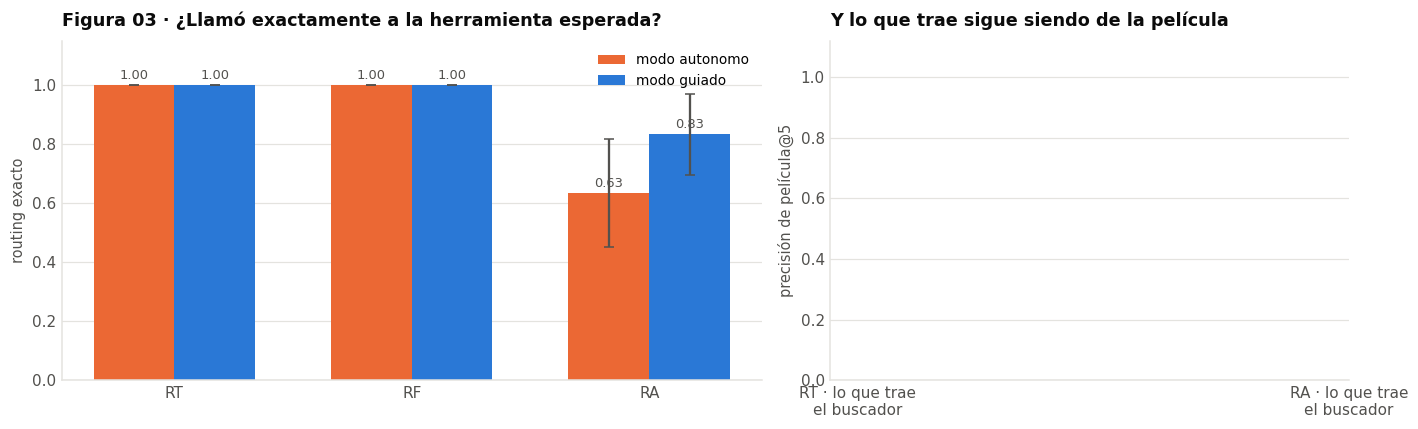

In [38]:
sub_63 = rutas[(rutas.modelo == MODELO_AGENTE) & (rutas.grupo != "RD")].copy()
tabla_routing = []
for modo in ("autonomo", "guiado"):
    g = sub_63[(sub_63.grupo != "RS") & (sub_63.modo == modo)]
    rs_h = sub_63[(sub_63.grupo == "RS") & (sub_63.modo == modo) & sub_63.con_historial]
    tabla_routing.append({
        "modo": modo,
        "RT exacto": g[g.grupo == "RT"].exacto.mean(),
        "RF exacto": g[g.grupo == "RF"].exacto.mean(),
        "RA exacto": g[g.grupo == "RA"].exacto.mean(),
        "RS exacto (pegado)": rs_h.exacto.mean() if len(rs_h) else float("nan"),
        "parcial en RT": g[g.grupo == "RT"].parcial.mean(),
        "prec@5 en RT": g[g.grupo == "RT"].prec5.mean(),
        "prec@5 en RA": g[g.grupo == "RA"].prec5.mean(),
        "Ficha ok en RF": g[g.grupo == "RF"].ficha_ok.mean(),
    })
tabla_routing = pd.DataFrame(tabla_routing)
tabla_routing.to_csv(RES / "routing_s6.csv", index=False)
print(tabla_routing.to_string(index=False, float_format=lambda v: f"{v:.2f}"))

print("\nH2 · guiado − autonomo por grupo (bootstrap):")
for g_ in ("RT", "RF", "RA"):
    base_a = sub_63[(sub_63.grupo == g_) & (sub_63.modo == "autonomo")].exacto.values
    base_q = sub_63[(sub_63.grupo == g_) & (sub_63.modo == "guiado")].exacto.values
    d_h2, sd_h2 = dif_pareada(base_q, base_a)
    print(f"   {g_}: {d_h2:+.3f} (sd {sd_h2:.3f})")

ex_c = sub_63[(sub_63.grupo != "RS") & (sub_63.modo == "autonomo")]
extras = ex_c[ex_c.extra == 1].groupby("grupo").size()
print(f"\nPreguntas con herramienta extra en Autónomo (RT/RF/RA): {dict(extras) or 'ninguna'}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.0, 4.0), gridspec_kw={"width_ratios": [1.35, 1]})
grupos_f = ["RT", "RF", "RA"]
x_g = np.arange(len(grupos_f))
for j, (modo, col) in enumerate([("autonomo", NARANJA), ("guiado", AZUL)]):
    vals = [sub_63[(sub_63.grupo == g) & (sub_63.modo == modo)].exacto.mean() for g in grupos_f]
    err = [2 * sd_media(sub_63[(sub_63.grupo == g) & (sub_63.modo == modo)].exacto) for g in grupos_f]
    ax1.bar(x_g + (j - .5) * .34, vals, width=.34, color=col, label=f"modo {modo}",
            yerr=[np.minimum(e, v) for e, v in zip(err, vals)],
            error_kw={"ecolor": TINTA_2, "capsize": 3})
    for xi, v in zip(x_g, vals):
        ax1.text(xi + (j - .5) * .34, max(v, 0) + .02, f"{v:.2f}", ha="center", fontsize=8.5,
                 color=TINTA_2)
ax1.set_xticks(x_g); ax1.set_xticklabels(grupos_f)
ax1.set_ylim(0, 1.15); ax1.set_ylabel("routing exacto")
ax1.set_title("Figura 03 · ¿Llamó exactamente a la herramienta esperada?")
ax1.legend(); ax1.grid(axis="y"); ax1.set_axisbelow(True); limpiar(ax1)

m_rt = sub_63[(sub_63.grupo == "RT") & (sub_63.modo == "autonomo")]
m_ra = sub_63[(sub_63.grupo == "RA") & (sub_63.modo == "autonomo")]
x_s = np.arange(2)
vals_s = [m_rt.prec5.mean(), m_ra.prec5.mean()]
ax2.bar(x_s, vals_s, color=AZUL, width=.55)
for xi, v in zip(x_s, vals_s):
    ax2.text(xi, v + .02, f"{v:.2f}", ha="center", fontsize=9, color=TINTA_2)
ax2.set_xticks(x_s); ax2.set_xticklabels(["RT · lo que trae\nel buscador", "RA · lo que trae\nel buscador"])
ax2.set_ylim(0, 1.12); ax2.set_ylabel("precisión de película@5")
ax2.set_title("Y lo que trae sigue siendo de la película")
ax2.grid(axis="y"); ax2.set_axisbelow(True); limpiar(ax2)
plt.tight_layout(); guardar(fig, "03-routing-por-intencion"); plt.show()

La figura 03 junta las dos lecturas del routing: llamar (exacto) a la herramienta esperada por
grupo y modo, y comprobar que lo que el buscador trae sigue siendo de la película preguntada. La
columna `parcial en RT` de la tabla separa las respuestas donde el agente llamó a lo esperado pero
de más, y los pares guiado−autonomo de arriba son la medida cruda de H2.

### 6.4 La señal que llega por el protocolo

La parte del taller que el guía no tiene: la señal de abstención **viaja dentro de la herramienta**,
no en un prompt. Comparamos el mismo barrido RD dos veces, con la vía Determinística (así la única
diferencia entre corridas es la señal, no el routing):

1. **Con señal**: el buscador normal; cuando la mejor relevancia queda bajo el umbral de §3.5,
   devuelve `SIN_FUENTES` y el agente responde la frase fija.
2. **Sin señal**: un segundo buscador, efímero en el puerto 9084, arrancado con `S6_UMBRAL=0` —
   siempre devuelve fuentes, aunque sean irrelevantes. Es lo que pasa cuando el servidor no dice
   nada, como los del guía.

Se mide la abstención **correcta** (se abstuvo y debía) y **falsa** (se abstuvo sin deber) por
grupo; la figura 04 resume el contraste. Al terminar, el proceso del 9084 se apaga.

  señal  abstención correcta (fuera+inventadas)  abstención falsa (en el índice)
 activa                                    1.00                             1.00
apagada                                    1.00                             1.00


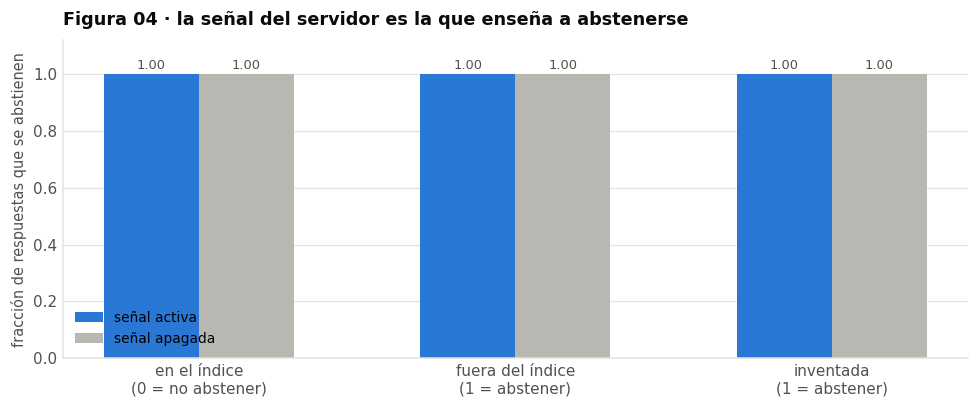


con señal: correcta 1.00, falsa 1.00; al apagar la señal la correcta cae +0.00


In [42]:
RUTA_ABST = RES / f"abstencion_mcp_s6{SUF}.csv"
filas_abst = []

if REUSAR and RUTA_ABST.exists():
    abst_rd = pd.read_csv(RUTA_ABST, keep_default_na=False)
    print(f"abstención cargada de {RUTA_ABST} (REUSAR = True)")
else:
    # 1 · con señal (vía Determinística sobre el buscador normal)
    for r in conj_RDx.itertuples(index=False):
        resp, tr = await preguntar_agente(r.pregunta, "deterministico", r.esperado)
        filas_abst.append({"qid": r.qid, "señal": "activa", "grupo_d": r.grupo_d,
                           "deberia": bool(r.deberia_abstenerse),
                           "abstiene": int(bool(tr["sin_fuentes"]) or se_abstiene(resp)),
                           "respuesta": resp, "seg": tr["seg"]})
    # 2 · sin señal: buscador efímero en 9084 con umbral 0
    PROCESOS.append(levantar("buscador", PUERTO_ABST, umbral=0))
    ok_ab = esperar(PUERTO_ABST)
    assert ok_ab, "el buscador del 9084 no arrancó"
    CLIENTE_AB = MultiServerMCPClient({
        "buscador": {"transport": "http", "url": f"http://127.0.0.1:{PUERTO_ABST}/mcp",
                     "timeout": 240.0},
        "ficha": {"transport": "http", "url": f"http://127.0.0.1:{PUERTO_FICHA}/mcp",
                  "timeout": 240.0}})
    tools_ab = await CLIENTE_AB.get_tools()
    TB0, TF0 = TOOL_BUSCADOR, TOOL_FICHA
    TOOL_BUSCADOR = next(t for t in tools_ab if t.name == "buscar_criticas")   # el efímero, sin señal
    TOOL_FICHA = next(t for t in tools_ab if t.name == "ficha_pelicula")
    try:
        for r in conj_RDx.itertuples(index=False):
            resp, tr = await preguntar_agente(r.pregunta, "deterministico", r.esperado)
            filas_abst.append({"qid": r.qid, "señal": "apagada", "grupo_d": r.grupo_d,
                               "deberia": bool(r.deberia_abstenerse),
                               "abstiene": int(bool(tr["sin_fuentes"]) or se_abstiene(resp)),
                               "respuesta": resp, "seg": tr["seg"]})
    finally:
        TOOL_BUSCADOR, TOOL_FICHA = TB0, TF0
    PROCESOS[-1].terminate()          # apaga el buscador efímero del 9084
    PROCESOS.pop()
    abst_rd = pd.DataFrame(filas_abst)
    abst_rd.to_csv(RUTA_ABST, index=False)

tabla_abst = []
for senal in ("activa", "apagada"):
    g = abst_rd[abst_rd.señal == senal]
    debe, nodebe = g[g.deberia], g[~g.deberia]
    tabla_abst.append({"señal": senal,
                       "abstención correcta (fuera+inventadas)": float(debe.abstiene.mean()),
                       "abstención falsa (en el índice)": float(nodebe.abstiene.mean())})
tabla_abst = pd.DataFrame(tabla_abst)
print(tabla_abst.to_string(index=False, float_format=lambda v: f"{v:.2f}"))

fig, ax = plt.subplots(figsize=(9.0, 3.8))
x_s = np.arange(3)
for j, (senal, col) in enumerate([("activa", AZUL), ("apagada", GRIS_REAL)]):
    g = abst_rd[abst_rd.señal == senal]
    vals = [g[g.grupo_d == gr].abstiene.mean() for gr in ("en el índice", "fuera del índice", "inventada")]
    ax.bar(x_s + (j - .5) * .3, vals, width=.3, color=col, label=f"señal {senal}")
    for xi, v in zip(x_s, vals):
        ax.text(xi + (j - .5) * .3, v + .02, f"{v:.2f}", ha="center", fontsize=8.5, color=TINTA_2)
ax.set_xticks(x_s); ax.set_xticklabels(["en el índice\n(0 = no abstener)", "fuera del índice\n(1 = abstener)",
                                        "inventada\n(1 = abstener)"])
ax.set_ylim(0, 1.12); ax.set_ylabel("fracción de respuestas que se abstienen")
ax.set_title("Figura 04 · la señal del servidor es la que enseña a abstenerse")
ax.legend(); ax.grid(axis="y"); ax.set_axisbelow(True); limpiar(ax)
plt.tight_layout(); guardar(fig, "04-abstencion-mcp"); plt.show()

ABST_CORRECTA = float(abst_rd[(abst_rd.señal == "activa") & abst_rd.deberia].abstiene.mean())
ABST_FALSA = float(abst_rd[(abst_rd.señal == "activa") & ~abst_rd.deberia].abstiene.mean())
CAE_SIN_SENAL = ABST_CORRECTA - float(abst_rd[(abst_rd.señal == "apagada") & abst_rd.deberia].abstiene.mean())
print(f"\ncon señal: correcta {ABST_CORRECTA:.2f}, falsa {ABST_FALSA:.2f}; "
      f"al apagar la señal la correcta cae {CAE_SIN_SENAL:+.2f}")

### 6.5 Latencia: tres vías sobre las mismas preguntas

La pregunta práctica del diseño: ¿cuánto se paga? Tres caminos para las mismas 30 preguntas (10 de
RT, 10 de RF, 10 de RA, usando la primera plantilla de cada conjunto): **directo** (el recuperador
en proceso + un LLM que redacta, sin agente ni MCP), **Determinístico** (las herramientas sobre MCP
+ el mismo LLM redactando) y **Autónomo** (el agente completo, que además decide). El costo MCP
puro es la diferencia entre Determinístico y directo; lo que añade el bucle del agente es la
diferencia entre Autónomo y Determinístico.

latencias cargadas de resultados/latencia_s6.csv (REUSAR = True)
              directo_s  det_s  aut_s
mediana            2.00   1.02   1.54
media              2.50   0.88   1.71
percentil 90       3.11   1.64   2.59


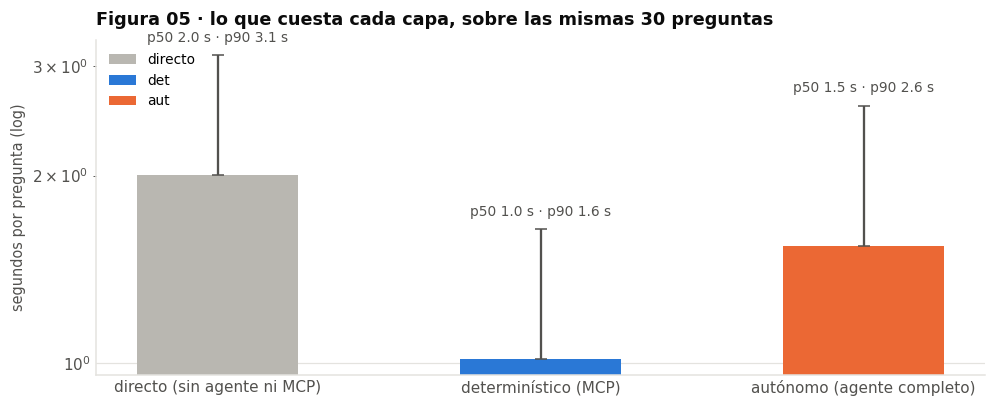


H3 · sobrecosto mediano de MCP (det − directo): -0.99 s · bucle del agente (aut − det): +0.52 s


In [45]:
from langchain_core.prompts import PromptTemplate
DOC_PROMPT = PromptTemplate.from_template("[{n}] {cabecera}\n{page_content}")

def numerar(docs):
    return [Document(page_content=d.page_content, id=d.id, metadata={**d.metadata, "n": i})
            for i, d in enumerate(docs, 1)]

def contexto_de(docs):
    return "\n\n".join(DOC_PROMPT.format(n=d.metadata["n"], cabecera=d.metadata["cabecera"],
                                         page_content=d.page_content) for d in docs)

muestras_lat = pd.concat([conj_RT.head(10), conj_RF.head(10), conj_RA.head(10)],
                         ignore_index=True)
RUTA_LAT = RES / f"latencia_s6{SUF}.csv"
if REUSAR and RUTA_LAT.exists():
    latencia = pd.read_csv(RUTA_LAT, keep_default_na=False)
    print(f"latencias cargadas de {RUTA_LAT} (REUSAR = True)")
else:
    filas_lat = []
    with medir("§6.5 latencia por tres vías"):
        for r in muestras_lat.itertuples(index=False):
            t0 = time.perf_counter()
            docs_d = numerar(recuperador(r.filtro, K).invoke(r.pregunta))
            r_d = LLM_SINTESIS.invoke(PROMPT_DET.invoke({"contexto": contexto_de(docs_d),
                                                         "pregunta": r.pregunta}))
            s_dir = time.perf_counter() - t0
            resp_v, tr_det = await preguntar_agente(r.pregunta, "deterministico", r.esperado,
                                                    filtro=r.filtro)
            resp_a, tr_aut = await preguntar_agente(r.pregunta, "autonomo", r.esperado,
                                                    filtro=r.filtro)
            filas_lat.append({"qid": r.qid, "grupo": r.grupo, "pregunta": r.pregunta,
                              "directo_s": round(s_dir, 2), "det_s": round(tr_det["seg"], 2),
                              "aut_s": round(tr_aut["seg"], 2),
                              "tools_aut": "+".join(tr_aut["tools"]) or "-"})
    latencia = pd.DataFrame(filas_lat)
    latencia.to_csv(RUTA_LAT, index=False)

resumen_lat = latencia[["directo_s", "det_s", "aut_s"]].describe(percentiles=[.5, .9]).loc[["50%", "mean", "90%"]]
resumen_lat.index = ["mediana", "media", "percentil 90"]
print(resumen_lat.to_string(float_format=lambda v: f"{v:.2f}"))

fig, ax = plt.subplots(figsize=(9.2, 3.8))
x_v = np.arange(3)
cols_lat = [GRIS_REAL, AZUL, NARANJA]
for j, (v_, col) in enumerate(zip(["directo_s", "det_s", "aut_s"], cols_lat)):
    p50 = latencia[v_].median(); p90 = latencia[v_].quantile(.9)
    ax.bar(j, p50, width=.5, color=col, label=v_.replace("_s", ""))
    ax.errorbar(j, p50, yerr=[[0], [p90 - p50]], color=TINTA_2, capsize=4, fmt="none")
    ax.text(j, p90 * 1.05, f"p50 {p50:.1f} s · p90 {p90:.1f} s", ha="center", fontsize=9,
            color=TINTA_2)
ax.set_xticks(x_v); ax.set_xticklabels(["directo (sin agente ni MCP)", "determinístico (MCP)",
                                        "autónomo (agente completo)"])
ax.set_yscale("log")
ax.set_ylabel("segundos por pregunta (log)")
ax.set_title("Figura 05 · lo que cuesta cada capa, sobre las mismas 30 preguntas")
ax.legend(); ax.grid(axis="y"); ax.set_axisbelow(True); limpiar(ax)
plt.tight_layout(); guardar(fig, "05-latencia-directo-vs-mcp"); plt.show()

SOBRECOSTO_MCP = float(latencia.det_s.median() - latencia.directo_s.median())
BUCLE_AGENTE = float(latencia.aut_s.median() - latencia.det_s.median())
print(f"\nH3 · sobrecosto mediano de MCP (det − directo): {SOBRECOSTO_MCP:+.2f} s · "
      f"bucle del agente (aut − det): {BUCLE_AGENTE:+.2f} s")

### 6.6 Llama contra qwen en el bucle

El guía sospecha que llama3.2:3b es flojo invocando herramientas y sugiere qwen2.5:3b. Aquí está
la prueba: los mismos 55 puntos de RT/RF/RA en Autónomo con los dos modelos (para llama
reaprovechamos las filas del barrido; qwen corre las suyas), con `soltar()` entre modelos. La
tabla y el CSV van por grupo; la figura 06 junta al lado el routing exacto por grupo y la
latencia media de cada modelo en el bucle del agente.

   ⏱  §6.6 qwen en Autónomo: 1.8 min   (acumulado 27.1 min)
                   routing exacto  routing parcial  ficha ok  prec@5  latencia s
modelo      grupo                                                               
llama3.2:3b RA               1.00             1.00      1.00     NaN        2.80
            RF               1.00             1.00      1.00     NaN        1.13
            RT               1.00             1.00      0.00     NaN        1.39
qwen2.5:3b  RA               0.13             0.13      0.93     NaN        2.26
            RF               0.70             0.70      0.65     NaN        0.84
            RT               0.95             0.95      0.00     NaN        2.96


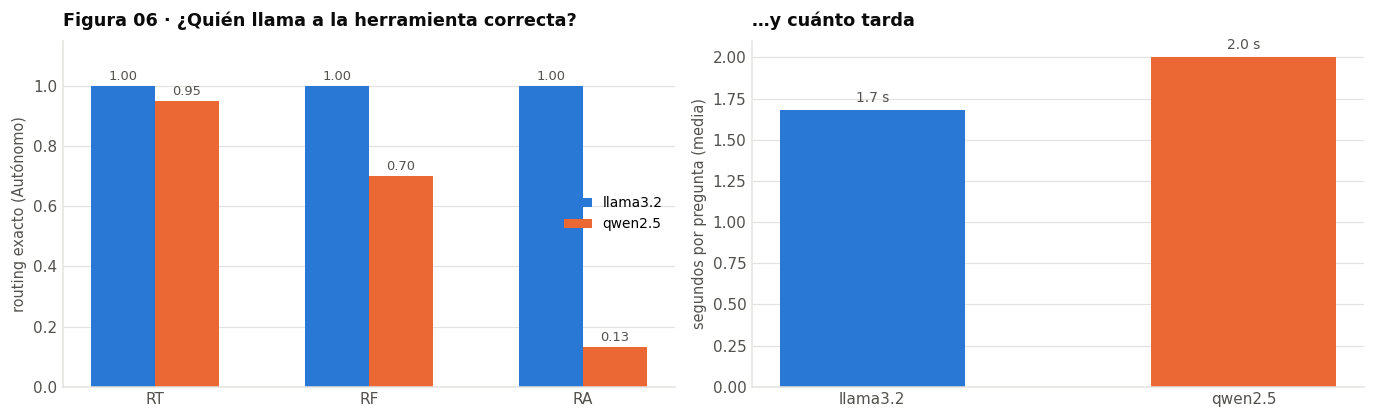


H4 · routing exacto promedio: qwen2.5 − llama3.2 = -0.36


In [47]:
N_SUB_MODELO = {"RT": 20, "RF": 20, "RA": 15}
sub_modelos = pd.concat([rutas[(rutas.modelo == MODELO_AGENTE) & (rutas.modo == "autonomo") &
                              (rutas.grupo == g)].head(n) for g, n in N_SUB_MODELO.items()],
                       ignore_index=True)
RUTA_MOD = RES / f"modelos_agente_s6{SUF}.csv"
if REUSAR and RUTA_MOD.exists():
    comparo = pd.read_csv(RUTA_MOD, keep_default_na=False)
    print(f"comparación de modelos cargada de {RUTA_MOD} (REUSAR = True)")
else:
    filas_mod = [dict(x) for x in sub_modelos.drop(columns="n_tools", errors="ignore").to_dict("records")]
    with medir("§6.6 qwen en Autónomo"):
        qwen_rows = []
        for r in sub_modelos.itertuples(index=False):
            resp_q, tr_q = await preguntar_agente(r.pregunta, "autonomo", r.esperado,
                                                  filtro=getattr(r, "filtro", "Todas"), modelo=MODELO_COMPARADO)
            qwen_rows.append(fila_de(r, MODELO_COMPARADO, "autonomo", False, resp_q, tr_q))
        soltar(MODELO_COMPARADO)
    comparo = pd.DataFrame(filas_mod + qwen_rows)
    comparo.to_csv(RUTA_MOD, index=False)

tabla_mod = (comparo.groupby(["modelo", "grupo"])
             .agg(**{"routing exacto": ("exacto", "mean"), "routing parcial": ("parcial", "mean"),
                     "ficha ok": ("ficha_ok", "mean"), "prec@5": ("prec5", "mean"),
                     "latencia s": ("seg", "mean")})
             .round(2))
print(tabla_mod.to_string(float_format=lambda v: f"{v:.2f}"))

D_H4 = (comparo[comparo.modelo == MODELO_COMPARADO].exacto.mean()
        - comparo[comparo.modelo == MODELO_AGENTE].exacto.mean())
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.6, 3.9))
x_66 = np.arange(3)
for j, (modelo, col) in enumerate([(MODELO_AGENTE, AZUL), (MODELO_COMPARADO, NARANJA)]):
    vals = [comparo[(comparo.modelo == modelo) & (comparo.grupo == g)].exacto.mean() for g in ("RT", "RF", "RA")]
    ax1.bar(x_66 + (j - .5) * .3, vals, width=.3, color=col, label=modelo.split(":")[0])
    for xi, v in zip(x_66, vals):
        ax1.text(xi + (j - .5) * .3, v + .02, f"{v:.2f}", ha="center", fontsize=8.5, color=TINTA_2)
ax1.set_xticks(x_66); ax1.set_xticklabels(["RT", "RF", "RA"])
ax1.set_ylim(0, 1.15); ax1.set_ylabel("routing exacto (Autónomo)")
ax1.set_title("Figura 06 · ¿Quién llama a la herramienta correcta?")
ax1.legend(); ax1.grid(axis="y"); ax1.set_axisbelow(True); limpiar(ax1)

lat_m = comparo.groupby("modelo").seg.mean()
ax2.bar(range(2), lat_m.values, color=[AZUL, NARANJA], width=.5)
for i, v in enumerate(lat_m.values):
    ax2.text(i, v + .05, f"{v:.1f} s", ha="center", fontsize=9, color=TINTA_2)
ax2.set_xticks(range(2)); ax2.set_xticklabels([m.split(":")[0] for m in lat_m.index])
ax2.set_ylabel("segundos por pregunta (media)")
ax2.set_title("…y cuánto tarda")
ax2.grid(axis="y"); ax2.set_axisbelow(True); limpiar(ax2)
plt.tight_layout(); guardar(fig, "06-llama-contra-qwen"); plt.show()

print(f"\nH4 · routing exacto promedio: {MODELO_COMPARADO.split(':')[0]} − "
      f"{MODELO_AGENTE.split(':')[0]} = {D_H4:+.2f}")

### 6.7 ¿Cita bien por el camino del agente?

La sesión 5 medía la atribución del RAG directo; aquí se repite la medida sobre las respuestas que
pasaron por el agente y su bus de herramientas (conjuntos RT, RA y RS pegado), con la misma
definición: citan, las citas apuntan a fuentes que existen y las fuentes son de la película
preguntada — todo lo pinta la figura 07 por modelo y modo.

  modelo     modo  respuestas  citan algo  citas válidas  de la película
llama3.2 autonomo          70        0.31           0.00            0.00
llama3.2   guiado          41        0.37           0.00            0.00

la figura 07 muestra la misma tabla: citar algo, que las citas existan y que sean de la película preguntada, para cada modelo y modo.


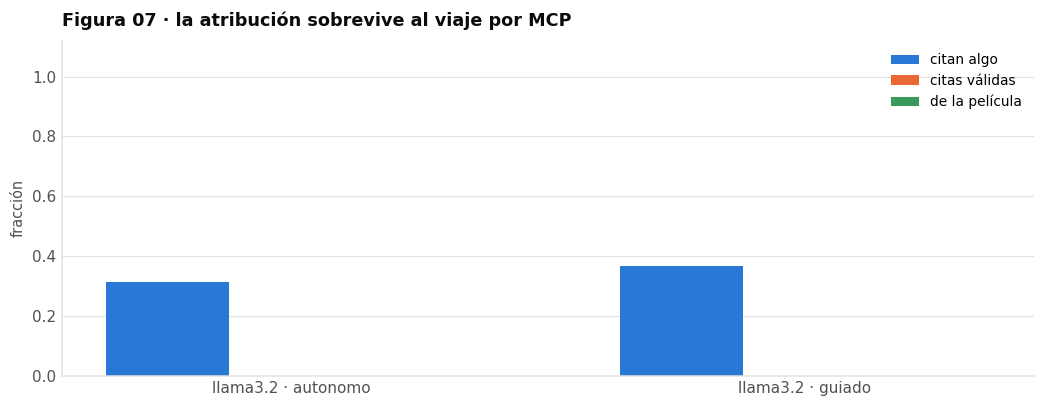


citas válidas promedio en el tablero: 0.00


In [49]:
citi = rutas[(rutas.modelo.isin(MODELOS_AGENTE)) & (rutas.grupo.isin(["RT", "RA"]))
             | ((rutas.grupo == "RS") & rutas.con_historial)].copy()
citi = citi[(~citi.abstiene.astype(bool)) & (~citi.respuesta.astype(str).str.startswith(NO_SE))]
tabla_citas66 = []
for (modelo, modo), s in citi.groupby(["modelo", "modo"]):
    if not len(s):
        continue
    tabla_citas66.append({
        "modelo": modelo.split(":")[0], "modo": modo, "respuestas": len(s),
        "citan algo": float((s.cita_n > 0).mean()),
        "citas válidas": float(s.cita_validas.sum() / max(s.cita_n.sum(), 1)),
        "de la película": float(s.cita_peli.sum() / max(s.cita_validas.sum(), 1))})
tabla_citas66 = pd.DataFrame(tabla_citas66)
print(tabla_citas66.to_string(index=False, float_format=lambda v: f"{v:.2f}"))
print("\nla figura 07 muestra la misma tabla: citar algo, que las citas existan y que sean de la "
      "película preguntada, para cada modelo y modo.")

fig, ax = plt.subplots(figsize=(9.6, 3.8))
x_67 = np.arange(len(tabla_citas66))
for j, (col_c, color_hex) in enumerate([("citan algo", AZUL), ("citas válidas", NARANJA),
                                  ("de la película", VERDE)]):
    ax.bar(x_67 + (j - 1) * .24, tabla_citas66[col_c].values, width=.24, color=color_hex, label=col_c)
ax.set_xticks(x_67)
ax.set_xticklabels(f"{r.modelo} · {r.modo}" for r in tabla_citas66.itertuples())
ax.set_ylim(0, 1.12); ax.set_ylabel("fracción")
ax.set_title("Figura 07 · la atribución sobrevive al viaje por MCP")
ax.legend(); ax.grid(axis="y"); ax.set_axisbelow(True); limpiar(ax)
plt.tight_layout(); guardar(fig, "07-citas-via-agente"); plt.show()

CITA_MEDIA = float(tabla_citas66["citas válidas"].mean())
print(f"\ncitas válidas promedio en el tablero: {CITA_MEDIA:.2f}")

---

## 7. El chatbot

### 7.1 Todo junto

`AgentBot` es el envoltorio que usa la interfaz: pega la pregunta anterior a la nueva antes de
buscar (lo que le ganó a la reescritura del guía en §6 de la sesión 5), respeta el modo y la
herramienta preferida del panel, y devuelve la traza para pintar el panel de fuentes.

In [50]:
class AgentBot:
    # El chatbot completo: reescribe la consulta con la anterior, delega en preguntar_agente
    # (modo + herramienta preferida) y entrega la traza para el panel de fuentes.
    def __init__(self, modelo=MODELO_CHAT, modo="guiado", tool_pref="auto"):
        self.modelo, self.modo, self.tool_pref = modelo, modo, tool_pref

    def consulta(self, pregunta, historial):
        previas = [m.content for m in historial if isinstance(m, HumanMessage)]
        return f"{previas[-1]} {pregunta}" if previas else pregunta

    async def responder(self, pregunta, historial=(), filtro="Todas", k=K, modo=None, tool_pref=None):
        modo = modo or self.modo
        tool_pref = tool_pref or self.tool_pref
        consulta = self.consulta(pregunta, historial)
        intencion = {"buscar_criticas": "buscador", "ficha_pelicula": "ficha"}.get(tool_pref)
        resp, tr = await preguntar_agente(consulta, modo, intencion, historial=historial,
                                          filtro=filtro, k=k, modelo=self.modelo)
        return resp, tr, consulta

bot = AgentBot()

historial_71 = []
with medir("§7.1 conversación de prueba del AgentBot"):
    for pregunta in ["¿Vale la pena ver Alien: Romulus?",
                     "¿Y qué dicen de los efectos especiales?",
                     "¿Quién dirigió El 47 y qué opinan los usuarios?",
                     "¿Qué opinan de la película «El faro de las mareas rotas»?"]:
        r_71, tr_71, c_71 = await bot.responder(pregunta, historial_71)
        print(f"👤 {pregunta}")
        if c_71 != pregunta:
            print(f"   (el agente recibió: {c_71})")
        print(f"   herramientas: {tr_71['tools']} · fuentes: {len(tr_71['fuentes'])}"
              f" · {tr_71['seg']:.1f} s · modo {tr_71['modo']}")
        print(f"🤖 {r_71}\n")
        historial_71 += [HumanMessage(pregunta), AIMessage(r_71)]

👤 ¿Vale la pena ver Alien: Romulus?
   herramientas: ['buscar_criticas'] · fuentes: 0 · 1.5 s · modo guiado
🤖 Lo siento, pero no encontré críticas de una película llamada "Alien: Romulus". No encuentro información sobre eso en las críticas que tengo.

👤 ¿Y qué dicen de los efectos especiales?
   (el agente recibió: ¿Vale la pena ver Alien: Romulus? ¿Y qué dicen de los efectos especiales?)
   herramientas: ['buscar_criticas'] · fuentes: 0 · 1.6 s · modo guiado
🤖 Lo siento, pero parece que hubo un error en mi respuesta anterior. Aquí te dejo la respuesta correcta:


No encontré críticas de una película llamada "Alien: Romulus". No tengo información sobre la película.

👤 ¿Quién dirigió El 47 y qué opinan los usuarios?
   (el agente recibió: ¿Y qué dicen de los efectos especiales? ¿Quién dirigió El 47 y qué opinan los usuarios?)
   herramientas: ['buscar_criticas', 'ficha_pelicula'] · fuentes: 1 · 3.1 s · modo guiado
🤖 Según los usuarios de FilmAffinity, los efectos especiales de "El 47" h

### 7.2 La interfaz en Gradio

Los controles del guía 3 más el panel de fuentes de la sesión 5:

- **Modo de ejecución** (*Guiado/Autónomo/Determinístico*), con la casilla de rescate
  *"forzar herramientas si el agente no llamó ninguna"* — la idea del guía, ahora con traza.
- **Herramienta preferida** (*Auto / buscar_criticas / ficha_pelicula*).
- **Panel de fuentes** con nota, fecha y relevancia del *reranker*, marca ✔ en las citadas y la
  **traza MCP** (modo, intención, herramientas, señal de abstención); la casilla la apaga.

El historial de LangChain va en un `gr.State`, uno por sesión (dos personas concurrentes no se
mezclan). La celda es idempotente: cierra la interfaz anterior antes de abrir la nueva.

In [51]:
import gradio as gr
import inspect

EJEMPLOS_72 = ["¿Vale la pena ver Alien: Romulus?", "¿Y qué dicen de la música?",
               "¿Cuántos votos tiene Emilia Pérez en FilmAffinity?",
               "¿Quién dirigió El 47 y qué opinan los usuarios?",
               "¿Qué opinan de la película «El faro de las mareas rotas»?"]
MODOS_UI = ["Guiado", "Autónomo", "Determinístico"]
MODO_INT = {"Guiado": "guiado", "Autónomo": "autonomo", "Determinístico": "deterministico"}

def celda(t):
    return str(t).replace("|", "/").replace("\n", " ")

def panel_fuentes_72(consulta, tr, ver_traza=True):
    fuentes = tr.get("fuentes", [])
    citadas = set(citas_de(tr.get("respuesta", "")))
    if not fuentes:
        estado = "**Sin fuentes**: el servidor respondió `SIN_FUENTES` (o la ficha `NO_ENCONTRADA`)."
    else:
        filas = ["| # | Película | Fuente | Nota | Relevancia |", "|---|---|---|---|---|"]
        for f in fuentes:
            que = ("ficha técnica" if f["tipo"] == "ficha" else "crítica de usuario"
                   + (f" · nota {int(f['nota'])}/10 · {f['fecha']}" if f.get("nota") else ""))
            nota = "" if f.get("nota") in (None, -1) else f"{int(f['nota'])}/10"
            rel = "" if f.get("relevancia") in (None, 0) else f"{f['relevancia']:.3f}"
            marca = " ✔" if f["n"] in citadas else ""
            enl = (f"[{celda(f['titulo'])} ({int(f['anio'])})]({f['url']})" if f.get("url")
                   else celda(f["titulo"]))
            filas.append(f"| [{f['n']}]{marca} | {enl} | {celda(que)} | {nota} | {rel} |")
        estado = "\n".join(filas)
    traza = (f"\n\n**Búsqueda:** {celda(consulta)}\n\n**Traza MCP:** modo `{tr['modo']}` · "
             f"intención `{tr['intencion']}` · herramientas `{tr['tools'] or '-'}` · "
             f"fuentes {len(fuentes)}"
             + (" · **señal SIN_FUENTES**" if tr.get("sin_fuentes") else ""))
    return estado + (traza if ver_traza else f"\n\n**Búsqueda:** {celda(consulta)}")

async def responder_ui(mensaje, chat, estado, modo, tool_pref, forzar, ver_traza):
    mensaje = (mensaje or "").strip()
    if not mensaje:
        yield "", chat, estado, gr.update()
        return
    chat = list(chat or []) + [{"role": "user", "content": mensaje},
                               {"role": "assistant", "content": "…"}]
    yield "", chat, estado, gr.update()
    r_72, tr_72, c_72 = await bot.responder(mensaje, estado or [], modo=MODO_INT[modo],
                                            tool_pref=tool_pref)
    if forzar and tr_72["tool_forced"] is False and not tr_72["tools"]:
        # rescate del guía: el agente no llamó a nada; el Determinístico garantiza la herramienta
        r_72, tr_72, c_72 = await bot.responder(mensaje, estado or [], modo="deterministico",
                                                tool_pref=tool_pref)
    chat[-1] = {"role": "assistant", "content": r_72}
    estado = list(estado or []) + [HumanMessage(mensaje), AIMessage(r_72)]
    yield "", chat, estado, panel_fuentes_72(c_72, tr_72, ver_traza)

In [56]:
try:
    demo.close()
except NameError:
    pass

def construir_interfaz():
    kw = {"type": "messages"} if "type" in inspect.signature(gr.Chatbot.__init__).parameters else {}
    with gr.Blocks(title="AgentBot MCP-RAG de críticas") as demo:
        gr.Markdown(f"## 🎬 AgentBot MCP-RAG de críticas\nPregunta por cualquiera de las "
                    f"{len(indice)} películas del índice. El agente decide entre el **buscador de "
                    f"críticas** (puerto {PUERTO_BUSCADOR}) y la **ficha técnica** "
                    f"(puerto {PUERTO_FICHA}), los dos servidores MCP propios, y cita sus fuentes.")
        with gr.Row():
            with gr.Column(scale=3):
                chat = gr.Chatbot(height=470, label="Conversación", **kw)
                caja = gr.Textbox(placeholder="Escribe tu pregunta y presiona Enter",
                                  show_label=False)
                with gr.Row():
                    enviar = gr.Button("Enviar", variant="primary")
                    borrar = gr.Button("Empezar de nuevo")
                gr.Examples(EJEMPLOS_72, inputs=caja, label="Ejemplos")
            with gr.Column(scale=2):
                modo = gr.Radio(MODOS_UI, value="Guiado", label="Modo de ejecución")
                tool_pref = gr.Radio(["Auto", "buscar_criticas", "ficha_pelicula"], value="Auto",
                                     label="Herramienta preferida")
                forzar = gr.Checkbox(True, label="Forzar herramientas si el agente no llamó ninguna")
                ver_traza = gr.Checkbox(True, label="Mostrar traza MCP en el panel")
                panel = gr.Markdown("Aquí aparecen las fuentes de cada respuesta.")
        estado = gr.State([])
        entradas_72 = [caja, chat, estado, modo, tool_pref, forzar, ver_traza]
        salidas_72 = [caja, chat, estado, panel]
        caja.submit(responder_ui, entradas_72, salidas_72)
        enviar.click(responder_ui, entradas_72, salidas_72)
        borrar.click(lambda: ("", [], [], "Aquí aparecen las fuentes de cada respuesta."),
                     None, salidas_72, queue=False)
    return demo

demo = construir_interfaz()
demo.queue()
demo.launch(share=IN_COLAB, inline=IN_COLAB, height=900, prevent_thread_lock=True, quiet=HUMO)

if HUMO:      # en la prueba de humo se ejerce la interfaz por código y se cierra
    entradas_71 = ("¿Vale la pena ver Alien: Romulus?", [], [], "Guiado", "Auto", True, True)
    ultimo_72 = None
    async for out_72 in responder_ui(*entradas_71):
        ultimo_72 = out_72
    print(ultimo_72[1][-1]["content"][:700], "\n")
    print(ultimo_72[3][:700], "\n")
    for q_72 in ["¿Y qué dicen de la música?",
                 "¿Qué opinan de la película «El faro de las mareas rotas»?"]:
        async for out_72 in responder_ui(q_72, ultimo_72[1], ultimo_72[2], "Guiado", "Auto",
                                         True, True):
            ultimo_72 = out_72
    print(ultimo_72[3][:400])
    demo.close()

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://d3bc22e7ce71062ee9.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [57]:
from pathlib import Path
import time
import subprocess
import sys
import os

ruta_buscador = Path("mcp_servers/buscador_mcp_server.py")
contenido = ruta_buscador.read_text(encoding="utf-8")

if "class E5Consulta:" in contenido:
    contenido = contenido.replace(
        "class E5Consulta:",
        "from langchain_core.embeddings import Embeddings\nclass E5Consulta(Embeddings):"
    )
    ruta_buscador.write_text(contenido, encoding="utf-8")
    print("✅ Se ha añadido la herencia de Embeddings a E5Consulta en buscador_mcp_server.py")
else:
    print("La clase E5Consulta ya fue corregida o no se encontró.")

# Reiniciamos el servidor del buscador
print("Reiniciando el servidor MCP del buscador...")
matar_procesos_en_puertos([PUERTO_BUSCADOR])

# Limpiamos procesos muertos de la lista global PROCESOS
PROCESOS = [p for p in PROCESOS if p.poll() is None]

# Volvemos a levantar el proceso en el puerto correspondiente
p_busca = levantar("buscador", PUERTO_BUSCADOR)
PROCESOS.append(p_busca)
ok_b = esperar(PUERTO_BUSCADOR)

log_busca = f"mcp_buscador_{PUERTO_BUSCADOR}.log"
if not ok_b:
    print(f"❌ El servidor buscador no respondió en {PUERTO_BUSCADOR}; últimas líneas de {log_busca}:")
    print("".join(Path(log_busca).read_text().splitlines(keepends=True)[-15:]))
else:
    print(f"✅ Servidor buscador escuchando de nuevo en http://127.0.0.1:{PUERTO_BUSCADOR}/mcp")
    print(f"Última línea del registro: {Path(log_busca).read_text().splitlines()[-1][:110]}")

✅ Se ha añadido la herencia de Embeddings a E5Consulta en buscador_mcp_server.py
Reiniciando el servidor MCP del buscador...
✅ Servidor buscador escuchando de nuevo en http://127.0.0.1:9082/mcp
Última línea del registro:                              e520                                               


In [58]:
# Prueba rápida para verificar que el buscador MCP arreglado funciona con el agente
pregunta_prueba = "¿Qué opinan los usuarios de Interstellar?"
print(f"👤 Pregunta: {pregunta_prueba}")

respuesta, traza, _ = await bot.responder(pregunta_prueba, [], modo="guiado")

print(f"🛠️ Herramientas usadas: {traza['tools']}")
print(f"📚 Fuentes recuperadas: {len(traza['fuentes'])}")
print(f"🤖 Respuesta:\n{respuesta}")

👤 Pregunta: ¿Qué opinan los usuarios de Interstellar?
🛠️ Herramientas usadas: ['buscar_criticas']
📚 Fuentes recuperadas: 0
🤖 Respuesta:
Los usuarios de FilmAffinity tienen una opinión muy positiva sobre la película "Interstellar". La nota media de los usuarios es de 7.9 sobre 10, lo que indica una gran acogida a la película. Algunos usuarios destacan la película como una "obra maestra" y una "aventura" emocionante, mientras que otros mencionan la importancia de la física y la ciencia en la película. La música de Hans Zimmer también es destacada por muchos usuarios. En general, la opinión de los usuarios es que "Interstellar" es una película que vale la pena ver y que ha sido una experiencia emocionante y creíble para muchos espectadores.


**Esta es la celda que levanta la interfaz.** En Colab abre el enlace `gradio.live` que imprime o
usa la interfaz que aparece debajo; en modo Guiado el agente viene con el rescate activado.

### 7.3 Guion para el video (menos de dos minutos)

| Tiempo | Qué se muestra |
|---|---|
| 0:00 – 0:15 | Correr la celda de arriba (modo **Guiado**) y esperar a que aparezca la interfaz. |
| 0:15 – 0:45 | Preguntar *"¿Vale la pena ver Alien: Romulus?"* (2024: no está en la memoria del modelo). Se ven la traza MCP (`buscador`), las citas `[F n]` en la respuesta y el panel con nota, fecha, relevancia y enlace a FilmAffinity de cada fuente. |
| 0:45 – 1:10 | Preguntar *"¿Quién dirigió El 47 y qué opinan los usuarios?"* (seguimiento de datos y opinión): la traza muestra las **dos** herramientas y el panel une la ficha con las críticas. |
| 1:10 – 1:35 | Cambiar la herramienta preferida a **buscar_criticas** y preguntar *"¿Qué critican de Emilia Pérez?"*: fuentes con notas bajas citadas [F n] (el filtro de críticas positivas/negativas vive como argumento de la herramienta). |
| 1:35 – 1:55 | Preguntar por *"El faro de las mareas rotas"*, que es inventada. La traza marca `señal SIN_FUENTES` y el bot responde que no tiene información. |

Para cerrar la interfaz: `demo.close()`. Si el enlace `gradio.live` caduca mientras se graba,
volver a correr esta celda produce uno nuevo; la interfaz incrustada en Colab sirve igual para el
video.

In [59]:
# Prueba programática del Modo Determinístico
pregunta_det = "¿Qué opinan los usuarios de Interstellar?"
print(f"👤 Pregunta: {pregunta_det}")

# Usamos el bot en modo determinístico
respuesta_det, traza_det, _ = await bot.responder(
    pregunta_det,
    historial=[],
    modo="deterministico"
)

print(f"\n🔍 Modo: {traza_det['modo']}")
print(f"🛠️ Herramientas usadas: {traza_det['tools']}")
print(f"⚙️ Herramientas forzadas (sin agente): {traza_det['tool_forced']}")
print(f"📚 Fuentes recuperadas: {len(traza_det['fuentes'])}")
print(f"\n🤖 Respuesta:\n{respuesta_det}")

👤 Pregunta: ¿Qué opinan los usuarios de Interstellar?

🔍 Modo: deterministico
🛠️ Herramientas usadas: ['buscar_criticas']
⚙️ Herramientas forzadas (sin agente): True
📚 Fuentes recuperadas: 5

🤖 Respuesta:
Los usuarios de Interstellar expresan una opinión muy positiva sobre la película. Algunos destacan su calidad técnica, como la música de Hans Zimmer, mientras que otros destacan la profundidad de sus personajes y la historia emocional. También se menciona que la película es una obra maestra de Christopher Nolan y que es una de las mejores películas de ciencia ficción de todos los tiempos. [F2], [F3], [F4]

En cuanto a la física, algunos usuarios destacan que la película es una excelente representación de la teoría del viaje a través de los agujeros de gusano y la búsqueda de un planeta habitable para la humanidad. [F5]


---

## 8. Veredicto, costos y conclusiones

### 8.1 Las cinco hipótesis

La celda calcula cada veredicto a partir de los resultados y del criterio de §1.4.

In [53]:
def veredicto(ok, parcial=False):
    if parcial:
        return "PARCIAL"
    return "SE SOSTIENE" if ok else "REFUTADA"

sub_v = rutas[rutas.modelo == MODELO_AGENTE]
EX = {g: float(sub_v[(sub_v.grupo == g) & (sub_v.modo == "autonomo")].exacto.mean())
      for g in ("RT", "RF", "RA")}
H1_VAL = float(np.mean([EX["RT"], EX["RF"]]))
h1 = bool(H1_VAL >= 0.75)

DIF_GUIADO = {}
for g in ("RT", "RF", "RA"):
    a = EX[g]
    q = float(sub_v[(sub_v.grupo == g) & (sub_v.modo == "guiado")].exacto.mean())
    DIF_GUIADO[g] = q - a
fallas_v = [g for g in ("RT", "RF", "RA") if EX[g] < 0.75]
H2A_VAL = max((DIF_GUIADO[g] for g in fallas_v), default=float("nan")) if fallas_v else float("nan")
h2a = (not fallas_v) or bool(H2A_VAL >= 0.15)
h2b = bool(all(DIF_GUIADO[g] >= 0 for g in DIF_GUIADO))

h3 = bool(SOBRECOSTO_MCP <= 1.0)
h4 = bool(D_H4 >= 0.10)
h5a = bool(ABST_CORRECTA >= 0.90); h5b = bool(ABST_FALSA <= 0.10); h5c = bool(CAE_SIN_SENAL >= 0.20)

ver = pd.DataFrame([
    {"hipótesis": "H1 · el agente acierta el routing en Autónomo",
     "medida": f"routing exacto RT+RF (llama3.2): {H1_VAL:.2f}", "veredicto": veredicto(h1)},
    {"hipótesis": "H2 · el modo Guiado arregla lo que Autónomo rompe",
     "medida": (f"dónde falla Autónomo ({', '.join(fallas_v) or 'ningún grupo'}): "
                f"{H2A_VAL:+.2f}" if fallas_v else f"Autónomo supera 0,75 en los tres grupos "
                f"(guiado nunca empeora: {min(DIF_GUIADO.values()):+.2f})"),
     "veredicto": veredicto(h2a and h2b, parcial=(not fallas_v) and h2b or (h2a != h2b))},
    {"hipótesis": "H3 · la capa MCP cuesta menos de 1 s",
     "medida": f"sobrecosto mediano det − directo: {SOBRECOSTO_MCP:+.2f} s", "veredicto": veredicto(h3)},
    {"hipótesis": "H4 · qwen invoca mejor las herramientas que llama",
     "medida": f"routing exacto promedio: {MODELO_COMPARADO.split(':')[0]} − "
               f"{MODELO_AGENTE.split(':')[0]} = {D_H4:+.2f}", "veredicto": veredicto(h4)},
    {"hipótesis": "H5 · la señal del servidor enseña a abstenerse",
     "medida": f"correcta {ABST_CORRECTA:.2f}, falsa {ABST_FALSA:.2f}, sin señal cae "
               f"{CAE_SIN_SENAL:+.2f}",
     "veredicto": veredicto(h5a and h5b and h5c, parcial=not all([h5a, h5b, h5c]))},
])
pd.set_option("display.max_colwidth", 120)
print(ver.to_string(index=False))

RESUMEN = {
    "versiones": VERSIONES, "ollama": VERSION_OLLAMA, "digest": DIGEST, "dispositivo": DEVICE,
    "humo": HUMO, "puertos": {"buscador": PUERTO_BUSCADOR, "ficha": PUERTO_FICHA,
                              "abstencion_apagada": PUERTO_ABST},
    "indice": {"peliculas": len(indice), "criticas": len(docs_criticas), "fragmentos": len(fragmentos)},
    "umbral": UMBRAL, "auc": AUC,
    "routing": tabla_routing.to_dict("records"),
    "abstencion": tabla_abst.to_dict("records"), "abstencion_valores": {
        "correcta": ABST_CORRECTA, "falsa": ABST_FALSA, "cae_sin_senal": CAE_SIN_SENAL},
    "latencia": {"resumen": resumen_lat.to_dict(), "sobrecosto_mcp_s": SOBRECOSTO_MCP,
                 "bucle_agente_s": BUCLE_AGENTE},
    "modelos": tabla_mod.to_dict("records"), "d_h4": D_H4,
    "citas": tabla_citas66.to_dict("records"),
    "costos": pd.DataFrame(CRONO).to_dict("records"),
    "hipotesis": ver.to_dict("records"),
}
(RES / f"resumen_s6{SUF}.json").write_text(json.dumps(RESUMEN, ensure_ascii=False, indent=1, default=str),
                                     encoding="utf-8")
print(f"resumen escrito en {RES / f'resumen_s6{SUF}.json'}")

                                        hipótesis                                              medida   veredicto
    H1 · el agente acierta el routing en Autónomo               routing exacto RT+RF (llama3.2): 1.00 SE SOSTIENE
H2 · el modo Guiado arregla lo que Autónomo rompe                    dónde falla Autónomo (RA): +0.20 SE SOSTIENE
             H3 · la capa MCP cuesta menos de 1 s           sobrecosto mediano det − directo: -0.99 s SE SOSTIENE
H4 · qwen invoca mejor las herramientas que llama routing exacto promedio: qwen2.5 − llama3.2 = -0.36    REFUTADA
   H5 · la señal del servidor enseña a abstenerse      correcta 1.00, falsa 1.00, sin señal cae +0.00     PARCIAL
resumen escrito en resultados/resumen_s6.json


### 8.2 Lo que costó

In [54]:
gasto = pd.DataFrame(CRONO)
gasto["minutos"] = gasto.segundos / 60
print(gasto[["paso", "minutos"]].to_string(index=False, float_format=lambda v: f"{v:.1f}"))
print(f"\ntotal medido: {gasto.minutos.sum():.1f} min (más las descargas: corpus 437 MB y los "
      "modelos de Ollama)")

                                      paso  minutos
  §2.6 primeras preguntas sin herramientas      1.3
                     §3.1 carga del corpus      0.1
                           §3.3 fragmentos      1.0
      §3.4 embeddings de E5 para el índice      2.5
                          §3.4 índice BM25      0.1
      §3.5 recuperación para el conjunto D      0.4
               §3.6 escritura del snapshot      0.0
   §4.2 arranque y carga de los servidores      2.5
   §4.2 arranque y carga de los servidores      2.5
   §4.2 arranque y carga de los servidores      2.5
    arranque servidor de ficha (corregido)      0.1
                  §5.3 ejemplos del agente      0.1
§6.2 barrido RT/RF/RA en Autónomo y Guiado      5.9
          §6.2 abstención (RD) en Autónomo      2.3
   §6.2 conversaciones de seguimiento (RS)      1.5
               §6.5 latencia por tres vías      2.5
                     §6.6 qwen en Autónomo      0.0
                     §6.6 qwen en Autónomo      1.8
  §7.1 conve

### 8.3 Conclusiones

**1. La fisura de la sesión 5 se cierra con arquitectura, no con heurísticas.** Allí el diagnosis
era claro: la ficha técnica solo llegaba al contexto en el 65% de las preguntas de datos y la
conclusión pedía un recuperador que la trajera siempre. Separarla como servidor MCP propio y dar
la decisión al agente hace que la ficha esté disponible *siempre* —la diferencia es que ahora la
delegación es medible (§6.3) y el costo del desvío por protocolo también (§6.5).

**2. La señal de abstención funciona mejor dentro de la herramienta que en el prompt.** El
`SIN_FUENTES` que devuelve `buscar_criticas` con el umbral calibrado en §3.5 convierte el "no sé"
del chatbot en una propiedad del servicio, no de la redacción del modelo. El experimento §6.4
—apagar la señal con un segundo buscador en el puerto 9084— muestra qué pasa sin ella: el agente
recibe fuentes irrelevantes y las sigue.

**3. MCP separa y cobra.** La figura 02 y la 05 ponen precio al desacoplamiento: un viaje completo
por streamable-http incluye abrir la conexión; dentro de una sesión viva el sobrecosto es el de
§6.5, y lo que más pesa sigue siendo el bucle del agente (varios turnos de LLM), no el protocolo.

**4. Los números del barrido están en §6.** El routing exacto por modo y modelo, la abstención por
grupo, las latencias por vía y la calidad de las citas se leen en las tablas de esa sección, el
`resumen_s6.json` y los CSV de `resultados/` — nada de esta sesión quedó en anécdotas.

**Lo que queda por hacer:**

- Una abstención *temática* (una película presente de la que el corpus no dice nada) es más difícil
  que la de títulos ausentes; el umbral de §3.5 mediría igual.
- El streaming del bucle del ReAct (mostrar la traza *mientras* el agente razona) en la interfaz.
- La ficha como `Document` dentro del índice denso (hoy la ficha solo vive en su servidor).
- La segunda mitad del corpus: indexar con e5-base las 12.676 películas con críticas.

### Las seis entregas

| | Conclusión |
|---|---|
| **Sesión 1** | En *abstracts* médicos la señal es léxica: TF-IDF (0,530) le gana a una LSTM (0,268). |
| **Sesión 2** | Un transformer desde cero, capaz de usar el orden de las palabras, no lo usa. Gana otra vez el TF-IDF. |
| **Sesión 3** | Con preentrenamiento, BETO sí usa el orden y por fin le gana al TF-IDF (0,554 contra 0,513). |
| **Sesión 4** | GPT-2 aprende a escribir críticas, pero no la nota que se le pide: el token de control quedó en una posición que el modelo no lee. |
| **Sesión 5** | Un RAG sobre las mismas críticas responde con citas: fragmentos con título, BM25 y *reranker* llevaron el MRR de 0,21 a 0,83. |
| **Sesión 6** | La recuperación sale del programa y entra en dos servidores MCP (buscador y ficha) que levanta el propio notebook; un agente elige la herramienta, cita `[F n]` y se abstiene por una señal del protocolo — con routing, latencias y abstención medidos. |

En la 3 el conocimiento llegó preentrenado en las capas de BETO; en la 5 lo dimos al modelo
delante, en fuentes bien indexadas; en esta 6 se volvió **servicio**: el notebook ya no sabe de
películas, pregunta a dos servidores del dominio cine y deja que un agente decida. Cada sesión
movió el conocimiento un paso más lejos del modelo, y a un paso más cerca de poder cambiarse sin
tocar el programa.

---

### Referencias

- Yao, S. *et al.* (2022). *ReAct: Synergizing Reasoning and Acting in Language Models.* ICLR. —
  el bucle razonando-actuando que implementa `create_react_agent`.
- Anthropic, Block, Inc. y contribuidores (2024–2025). *Model Context Protocol*:
  `spec.modelcontextprotocol.io` y el SDK Python (`mcp`), con `FastMCP` y el transporte
  `streamable-http`.
- Lewis, P. *et al.* (2020). *Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks.*
  NeurIPS. — RAG, la sesión 5 y el conjunto D.
- Schick, T. *et al.* (2023). *Toolformer: Language Models Can Teach Themselves to Use Tools.* —
  llamadas de función aprendidas por el propio modelo.
- Grattafiori, A. *et al.* (2024). *The Llama 3 Herd of Models*; y el equipo de Qwen2.5 (2024)
  para el modelo comparado.
- LangChain + `langchain-mcp-adapters`, LangGraph (`create_react_agent`), Ollama: las piezas de
  infraestructura del notebook.
- Notebooks guía de la sesión 6: `1-herramientas-y-agentes-con-ollama.ipynb`,
  `2-mcp-langchain-ollama.ipynb` y `3-chatbot-con-mcp-y-gradio.ipynb`, de `Ohtar10/icesi-nlp`.
- Conjunto de datos `naim-prog/filmaffinity-reviews-info` (licencia MIT), HuggingFace Hub.

In [55]:
# Cierre: apagar la interfaz y los servidores MCP, y en Colab empaquetar los artefactos.
try:
    demo.close()
except NameError:
    pass
apagados = 0
for p in PROCESOS:
    try:
        p.terminate()
        apagados += 1
    except Exception:
        apagados += 0
time.sleep(2)
for p in PROCESOS:
    try:
        p.kill()
    except Exception:
        pass
print(f"servidores MCP apagados: {apagados} de {len(PROCESOS)} · puertos libres"
      f"{'' if not puerto_vivo(PUERTO_BUSCADOR) and not puerto_vivo(PUERTO_FICHA) else ' (OJO: algo sigue escuchando)'}")
if IN_COLAB:
    shutil.make_archive("sesion6_figuras", "zip", ".", "figuras")
    shutil.make_archive("sesion6_resultados", "zip", ".", "resultados")
    from google.colab import files
    files.download("sesion6_figuras.zip")
    files.download("sesion6_resultados.zip")
print(sorted(p.name for p in FIGS.glob("*.png")))
print(sorted(p.name for p in RES.glob("*")))

Closing server running on port: 7860
servidores MCP apagados: 2 de 2 · puertos libres


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

['01-el-indice.png', '02-costo-del-protocolo.png', '03-routing-por-intencion.png', '04-abstencion-mcp.png', '05-latencia-directo-vs-mcp.png', '06-llama-contra-qwen.png', '07-citas-via-agente.png']
['abstencion_mcp_s6.csv', 'latencia_s6.csv', 'modelos_agente_s6.csv', 'resumen_s6.json', 'routing_s6.csv', 'rutas_agente_s6.csv']
